# Lab Assignment 2: Corpus Analysis and Tokenization

**Student:** Muhammad Obaidullah (abdulsalam.m@northeastern.edu)  
**Course:** Applied NLP  
**Submission:** Upload `Lab_2.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

This lab develops your ability to read a corpus statistically — not just to process text, but to understand *what the numbers tell you* about the language and about the challenges your models will face. You will examine linguistic ambiguity as a fundamental obstacle for automated language understanding, analyze how word frequency follows Zipf's Law and what that implies for vocabulary design, and characterize a real corpus to identify the linguistic phenomena that make it hard to process automatically.

These are the analytical skills that distinguish a practitioner who understands their tools from one who merely applies them.

---

## Learning Objectives

By the end of this lab you will be able to:

1. Analyze real-world text examples to identify and classify types of linguistic ambiguity (lexical, structural, referential, morphological) and explain why each poses distinct challenges for NLP approaches
2. Apply Zipf's Law to analyze a corpus and evaluate how it influences model design decisions regarding vocabulary size and data sparsity
3. Analyze a text corpus to characterize its statistical properties and identify linguistic phenomena that would challenge automated processing

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1a — Classify each ambiguity example (4 examples × 2 pts) | 8 | Autograded |
| Part 1b — Explain the NLP challenge for each example (4 × 3 pts) | 12 | Manual |
| Part 2 — Zipf's Law analysis | 33 | Autograded (23 pts) + Manual (10 pts) |
| Part 3 — Corpus statistics and tokenization | 27 | Autograded |
| Code quality | 20 | Manual |
| **Total** | **100** | |

### Manual grading rubric

**Part 1b explanations (12 pts, 3 pts each):**  
A full-credit explanation names the *specific NLP task or operation* that is disrupted, explains *why* the ambiguity type makes it harder than the others would, and uses precise terminology. Saying "the computer doesn't know what the word means" earns 1 pt. Explaining that lexical ambiguity means a word-sense disambiguation step is required before downstream tasks like relation extraction can proceed earns 3 pts.

**Part 2 written interpretation (10 pts):**  
See Part 2 instructions for the specific prompts. Full credit requires connecting the observed statistics to concrete model design decisions, not just restating numbers.

**Code quality (20 pts):**

| Criterion | Points | What we look for |
|---|---|---|
| Docstrings and inline comments | 5 | Every function has a docstring (purpose, args, return). Non-obvious logic commented. |
| Function design | 5 | Reusable functions; no hard-coded values that should be parameters; one job per function. |
| Defensive coding | 4 | Input validation where it matters; no silent failures on edge cases. |
| Code clarity and naming | 3 | Descriptive names; reads like a narrative. |
| Avoiding redundancy | 3 | DRY principle applied; no copy-pasted logic. |

> **Note on rising expectations:** As with Lab 1, the code quality rubric is applied with some leniency here. The same gaps that receive partial credit in Lab 2 will receive deductions in later labs. If you are unsure whether your code meets a criterion, assume the standard will be higher next time.

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess, sys

def install_if_missing(package):
    """Install a package if it cannot be imported.

    Args:
        package (str): The importable package name to check and install.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])

install_if_missing("numpy")
install_if_missing("pandas")
install_if_missing("nltk")
install_if_missing("matplotlib")

import numpy as np
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

for resource in ["punkt", "punkt_tab", "stopwords", "brown"]:
    nltk.download(resource, quiet=True)

from nltk.corpus import brown
from nltk import FreqDist
from nltk.tokenize import word_tokenize, sent_tokenize

print("Environment ready.")

Environment ready.


---

## Part 1 — Linguistic Ambiguity (20 points)

Ambiguity is one of the central reasons natural language is hard to process automatically. Unlike formal languages such as SQL or Python, natural language sentences often have more than one valid interpretation — and humans resolve these effortlessly using context, world knowledge, and pragmatic inference that systems do not have access to by default.

J&M (Ch. 1 and Ch. 12–13) identifies several distinct types of ambiguity, each of which disrupts different stages of an NLP pipeline:

- **Lexical ambiguity** — a word has multiple possible meanings or parts of speech (*bank*, *duck*, *fine*)
- **Structural ambiguity** — a sentence has multiple valid parse trees, typically due to attachment or coordination (*I saw the man with the telescope*)
- **Referential ambiguity** — a pronoun or referring expression could resolve to more than one antecedent (*The city council refused the demonstrators a permit because **they** feared violence*)
- **Morphological ambiguity** — a word form maps to more than one morphological analysis (*flies* as verb or noun; *better* as adjective or verb)

### Instructions

Four sentences are given below. For each one:

**Part 1a (autograded):** Assign the correct ambiguity type to the corresponding variable. Use exactly one of these strings: `"lexical"`, `"structural"`, `"referential"`, `"morphological"`. Your answer is case-insensitive and may include the word "ambiguity" (e.g. `"lexical ambiguity"` is accepted).

**Part 1b (manually graded):** In the markdown cell below each sentence, write 3–5 sentences explaining:
  - What the two (or more) interpretations of the sentence are
  - Which *specific* NLP task or pipeline stage is disrupted by this type of ambiguity
  - Why this type of ambiguity is harder to resolve than the others would be in this case

---

### Example 1

> *"The chicken is ready to eat."*

This sentence has two readings. Identify the type of ambiguity and assign it below.

In [2]:
# Assign exactly one of: "lexical", "structural", "referential", "morphological"
# Case-insensitive; "lexical ambiguity" is also accepted.

ambiguity_type_1 = "structural"

**Your explanation (Part 1b):** The two readings differ in the argument structure of the embedded infinitive: either *the chicken* is the understood object (patient) of *eat*, so the cooked chicken is ready for someone to eat it, or it is the understood subject (agent), so the live chicken is ready to eat its feed. Every word carries the same part-of-speech tag in both readings, so POS tagging resolves nothing; the ambiguity lies in which position the phonologically empty argument of *eat* occupies (a subject-control versus *tough*-construction contrast). A surface parse attaches *chicken* to *ready* identically in both readings, so the disruption falls on recovering predicate-argument structure: an enhanced dependency parser must link *chicken* to *eat* as `nsubj` or `obj`, and semantic role labeling must assign it ARG0 or ARG1. This is harder than a lexical ambiguity would be because no single token holds the ambiguity: the meat/animal contrast on *chicken* follows from the structural choice rather than causing it, the missing argument has no token a model could label, and deciding requires context or world knowledge (a kitchen versus a farmyard) that the sentence does not supply.

---

### Example 2

> *"Visiting relatives can be boring."*

Two syntactically distinct structures produce two very different meanings. Identify the type of ambiguity.

In [3]:
ambiguity_type_2 = "structural"

**Your explanation (Part 1b):** In one reading *visiting* is a gerund heading the subject phrase and *relatives* is its object (the act of visiting one's relatives can be boring); in the other, *visiting* is a participial modifier of the noun *relatives* (relatives who are visiting can be boring). The disrupted stage is constituency/dependency parsing: the subject is either `[NP [VP visiting [NP relatives]]]`, headed by *visiting*, or `[NP [ADJP visiting] relatives]`, headed by *relatives*, and semantic role labeling inherits the choice, since *relatives* is the patient of *visit* in the first parse and its agent in the second. It is harder than a lexical ambiguity because every word keeps the same sense in both readings, and a Penn Treebank tagger will typically assign *visiting* `VBG` in both, so even an accurate POS tagger leaves the ambiguity intact. The modal *can* also neutralizes subject-verb agreement, the one morphosyntactic cue that would otherwise decide it (*visiting relatives **is** boring* versus ***are** boring*), so only the bracketing and head selection distinguish the readings.

---

### Example 3

> *"The trophy didn't fit in the suitcase because it was too big."*

The pronoun *it* is the source of ambiguity here. What type is this?

In [4]:
ambiguity_type_3 = "referential"

**Your explanation (Part 1b):** The pronoun *it* can grammatically corefer with either *the trophy* (the trophy was too big to fit) or *the suitcase* (the suitcase was too big); only the first reading is coherent, because a container being too large does not prevent something from fitting inside it. The disrupted task is coreference (anaphora) resolution, and the error propagates to everything built on resolved mentions, such as relation extraction, question answering, and summarization. The ambiguity is harder than the others here because there is nothing for earlier pipeline stages to fix: the words are unambiguous, the parse is unique, and both candidate antecedents share the same agreement features (third person, singular, neuter, inanimate), so feature-based filtering eliminates neither. This is a Winograd schema: replacing *big* with *small* flips the referent to *the suitcase* with no change in syntax, so heuristics such as subject preference or recency get one variant right only by chance, and resolution requires commonsense reasoning about physical size and containment.

---

### Example 4

> *"I saw her duck."*

Consider all the possible word-level analyses before settling on a type. (Hint: J&M use this exact sentence in Chapter 1.)

In [5]:
ambiguity_type_4 = "lexical"

**Your explanation (Part 1b):** In one reading *duck* is a noun and *her* is a possessive determiner, so I saw the duck that belongs to her (`[NP her duck]` is the object of *saw*); in the other, *duck* is a verb and *her* is an accusative pronoun, so I saw her lower her head (*her* is the subject of a bare-infinitive clause under the perception verb *saw*), and *saw* can additionally be read as the present tense of *saw* "to cut". I classify it as lexical because the noun/verb category of *duck* is the pivot: once *duck* is tagged `NN`, *her* must be `PRP$` and the complement must be a noun phrase; once it is tagged `VB`, *her* must be `PRP` and the complement must be a clause, so both the case ambiguity of *her* and the structural difference follow from that one decision. The first stage disrupted is POS tagging, and its error cascades into parsing and semantic role labeling (is *her* the possessor of an entity or the agent of an action?), while *saw* requires word-sense disambiguation between *see* and *cut*. It is not primarily morphological because *duck* is a bare stem with no affix, so there is no competing segmentation or inflectional analysis, only a choice between two lexical entries (the notebook's own lexical example); the one morphological wrinkle, *saw* as *see*+PAST versus the base form of *saw*, is also a choice between two lexemes, and resolving it removes far less ambiguity than resolving *duck*. It is hard for a tagger because the local context *her ___* frequently licenses both `PRP$ NN` and `PRP VB`, so the sentence offers no internal evidence to decide between them.

> **Note:** Example 4 involves more than one type of ambiguity. Your classification should name the *primary* type — the one that, if resolved, would most reduce the remaining ambiguity. Explain your reasoning.

---

## Part 2 — Zipf's Law Analysis (33 points)

Zipf's Law states that in any natural language corpus, the frequency of a word is approximately inversely proportional to its rank by frequency. Formally:

$$f(w) \propto \frac{1}{\text{rank}(w)^s}$$

where *s* is close to 1 for natural language. This has profound practical consequences: a tiny number of words account for most of the tokens in any corpus, while the vast majority of the vocabulary is rare. Understanding this is essential for decisions about vocabulary size, unknown-word handling, and data sparsity in language models.

In this part you will compute and visualize Zipf's Law for the Brown corpus news category, fit a line in log-log space to measure the Zipf exponent, compute coverage thresholds, and compare two corpus domains.

### 2.1 — Load the corpus and build a frequency distribution

In [6]:
CORPUS_CATEGORY_A = 'news'
CORPUS_CATEGORY_B = 'fiction'


def require_non_empty(values, name):
    """Raise a ValueError if a sized collection is empty.

    Shared guard used by every function below so that an empty corpus or
    array fails loudly instead of producing NaNs or division-by-zero errors.

    Args:
        values: Any object supporting len() (list, np.ndarray, FreqDist, ...).
        name (str): Human-readable name of the argument, used in the message.

    Raises:
        ValueError: If ``values`` has length zero.
    """
    if len(values) == 0:
        raise ValueError(f"{name} is empty; at least one element is required.")


def validate_category(corpus, category):
    """Check that ``category`` is a non-empty string known to ``corpus``.

    Args:
        corpus: An NLTK categorized corpus object with a .categories() method.
        category (str): The category name to validate.

    Raises:
        TypeError: If ``category`` is not a string.
        ValueError: If ``category`` is empty or not one of the corpus categories.
    """
    if not isinstance(category, str):
        raise TypeError(f"category must be a str, got {type(category).__name__}.")
    if not category:
        raise ValueError("category must be a non-empty string.")
    available = corpus.categories()
    if category not in available:
        raise ValueError(f"Unknown category {category!r}; available: {available}.")


def load_and_tokenize(corpus, category):
    """Load a Brown corpus category and return a list of lowercase tokens.

    Includes all word tokens (punctuation included, consistent with standard
    corpus analysis practice).

    Args:
        corpus: An NLTK corpus object with a .words() method.
        category (str): The corpus category name.

    Returns:
        list[str]: Lowercased token list.
    """
    validate_category(corpus, category)
    # Case-folding merges sentence-initial "The" with "the", so frequency
    # counts reflect word types rather than capitalisation variants.
    tokens = [token.lower() for token in corpus.words(categories=category)]
    require_non_empty(tokens, f"Token list for category {category!r}")
    return tokens

tokens_news    = load_and_tokenize(brown, CORPUS_CATEGORY_A)
tokens_fiction = load_and_tokenize(brown, CORPUS_CATEGORY_B)

print(f"'news'    tokens: {len(tokens_news):,}")
print(f"'fiction' tokens: {len(tokens_fiction):,}")

'news'    tokens: 100,554
'fiction' tokens: 68,488


### 2.2 — Compute rank-frequency data

Build a frequency distribution and extract sorted rank-frequency arrays. These arrays are the foundation for all Zipf analysis below.

In [7]:
def build_rank_freq_arrays(tokens):
    """Build a FreqDist from tokens and return sorted rank and frequency arrays.

    Args:
        tokens (list[str]): List of tokens.

    Returns:
        tuple: (fdist, ranks, freqs) where
            fdist  — nltk.FreqDist
            ranks  — np.ndarray of integer ranks (1 = most frequent)
            freqs  — np.ndarray of corresponding frequencies (descending)
    """
    require_non_empty(tokens, "tokens")
    fdist = FreqDist(tokens)
    # most_common() with no argument returns every (type, count) pair sorted
    # by descending count, which is exactly the rank order Zipf's law needs.
    freqs = np.array([count for _, count in fdist.most_common()], dtype=np.int64)
    ranks = np.arange(1, len(freqs) + 1, dtype=np.int64)
    return fdist, ranks, freqs

fdist_news,    ranks_news,    freqs_news    = build_rank_freq_arrays(tokens_news)
fdist_fiction, ranks_fiction, freqs_fiction = build_rank_freq_arrays(tokens_fiction)

print(f"News vocab size:    {len(fdist_news):,}")
print(f"Fiction vocab size: {len(fdist_fiction):,}")
print(f"Top 5 news words:    {fdist_news.most_common(5)}")
print(f"Top 5 fiction words: {fdist_fiction.most_common(5)}")

News vocab size:    13,112
Fiction vocab size: 8,680
Top 5 news words:    [('the', 6386), (',', 5188), ('.', 4030), ('of', 2861), ('and', 2186)]
Top 5 fiction words: [('the', 3792), (',', 3654), ('.', 3639), ('and', 1770), ('to', 1508)]


### 2.3 — Fit the Zipf exponent

In log-log space, Zipf's Law is a straight line:

$$\log(f) = b - s \cdot \log(r)$$

Fit this line using `np.polyfit` on the log-transformed rank and frequency arrays. The slope *−s* is the Zipf exponent; for natural language it should be close to −1.

In [8]:
def validate_rank_freq(ranks, freqs):
    """Validate paired rank/frequency arrays before taking logarithms.

    Args:
        ranks (array-like): Ranks, one per word type.
        freqs (array-like): Frequencies aligned with ``ranks``.

    Returns:
        tuple[np.ndarray, np.ndarray]: The inputs as 1-D float arrays.

    Raises:
        ValueError: If the arrays are empty, not 1-D, differ in length, or
            contain non-positive values (log is undefined at or below zero).
    """
    ranks = np.asarray(ranks, dtype=float)
    freqs = np.asarray(freqs, dtype=float)
    require_non_empty(ranks, "ranks")
    if ranks.ndim != 1 or freqs.ndim != 1:
        raise ValueError("ranks and freqs must be 1-D arrays.")
    if ranks.shape != freqs.shape:
        raise ValueError(f"ranks and freqs differ in length: {ranks.size} vs {freqs.size}.")
    if np.any(ranks <= 0) or np.any(freqs <= 0):
        raise ValueError("ranks and freqs must be strictly positive to take logarithms.")
    return ranks, freqs


def fit_zipf(ranks, freqs):
    """Fit Zipf's Law in log-log space using least-squares linear regression.

    Args:
        ranks (np.ndarray): Array of integer ranks (1-indexed, ascending).
        freqs (np.ndarray): Array of corresponding frequencies (descending).

    Returns:
        tuple: (slope, intercept) of the log-log linear fit.
            slope is the Zipf exponent (negative; close to -1 for natural language).
    """
    ranks, freqs = validate_rank_freq(ranks, freqs)
    if ranks.size < 2:
        raise ValueError("At least two (rank, freq) points are needed to fit a line.")
    # Natural log on both axes: log f = intercept + slope * log r. The slope is
    # base-invariant; the intercept is in natural-log units, so plot_zipf
    # reconstructs the line with np.exp.
    slope, intercept = np.polyfit(np.log(ranks), np.log(freqs), deg=1)
    return float(slope), float(intercept)

zipf_slope_news,    zipf_intercept_news    = fit_zipf(ranks_news,    freqs_news)
zipf_slope_fiction, zipf_intercept_fiction = fit_zipf(ranks_fiction, freqs_fiction)

zipf_slope_news    = round(float(zipf_slope_news), 4)
zipf_slope_fiction = round(float(zipf_slope_fiction), 4)

print(f"Zipf slope — news:    {zipf_slope_news}  (ideal: -1.0)")
print(f"Zipf slope — fiction: {zipf_slope_fiction}  (ideal: -1.0)")

Zipf slope — news:    -1.0204  (ideal: -1.0)
Zipf slope — fiction: -1.0039  (ideal: -1.0)


### 2.4 — Visualize Zipf's Law

Plot the rank-frequency distribution in log-log space for both categories on the same axes, and overlay the fitted lines.

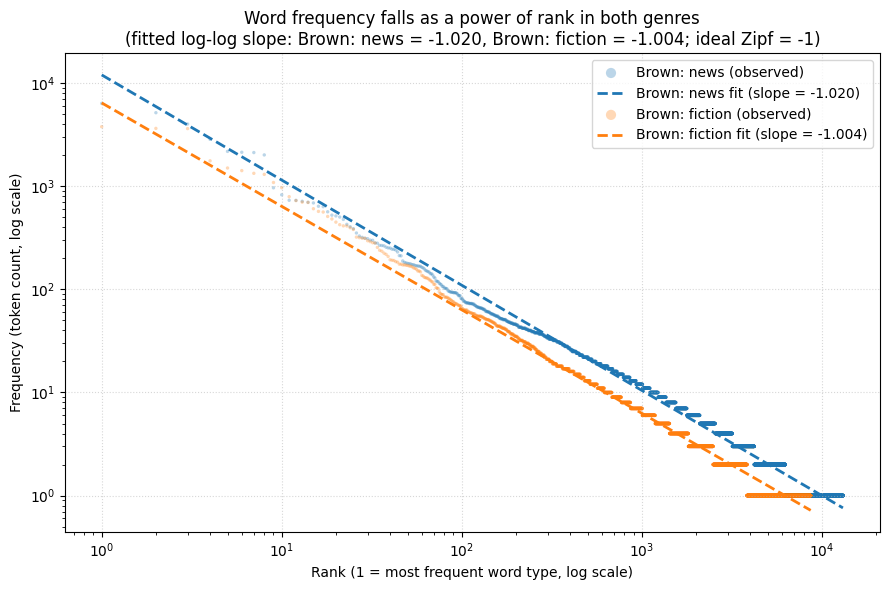

In [9]:
def plot_corpus_rank_freq(ax, ranks, freqs, slope, intercept, label, color,
                          marker_size, alpha):
    """Draw one corpus's rank-frequency scatter and its fitted Zipf line on ``ax``.

    Args:
        ax (matplotlib.axes.Axes): Target axes (expected to use log-log scales).
        ranks, freqs (np.ndarray): Rank and frequency arrays for the corpus.
        slope, intercept (float): Natural-log fit parameters from fit_zipf.
        label (str): Corpus name used in the legend.
        color (str): Matplotlib colour shared by the scatter and the fitted line.
        marker_size (float): Scatter marker area.
        alpha (float): Scatter opacity.
    """
    ranks, freqs = validate_rank_freq(ranks, freqs)
    ax.scatter(ranks, freqs, s=marker_size, alpha=alpha, color=color,
               edgecolors="none", label=f"{label} (observed)")
    # Invert the natural-log fit: log f = b + s log r  =>  f = e^b * r^s
    fitted_freqs = np.exp(intercept) * ranks ** slope
    ax.plot(ranks, fitted_freqs, color=color, linewidth=2, linestyle="--",
            label=f"{label} fit (slope = {slope:.3f})")


def plot_zipf(ranks_a, freqs_a, slope_a, intercept_a, label_a,
              ranks_b, freqs_b, slope_b, intercept_b, label_b,
              colors=("tab:blue", "tab:orange"), marker_size=6, alpha=0.3,
              figsize=(9, 6)):
    """Plot two rank-frequency distributions in log-log space with fitted lines.

    Args:
        ranks_a, freqs_a: Rank and frequency arrays for corpus A.
        slope_a, intercept_a: Zipf fit parameters for corpus A.
        label_a (str): Legend label for corpus A.
        ranks_b, freqs_b: Rank and frequency arrays for corpus B.
        slope_b, intercept_b: Zipf fit parameters for corpus B.
        label_b (str): Legend label for corpus B.
        colors (tuple[str, str]): Colours for corpus A and corpus B.
        marker_size (float): Scatter marker area.
        alpha (float): Scatter opacity (low values keep dense regions readable).
        figsize (tuple[float, float]): Figure size in inches.

    Returns:
        tuple: (fig, ax) matplotlib figure and axes objects.
    """
    if len(colors) != 2:
        raise ValueError("colors must contain exactly two entries (corpus A, corpus B).")

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xscale("log")
    ax.set_yscale("log")

    corpora = [
        (ranks_a, freqs_a, slope_a, intercept_a, label_a),
        (ranks_b, freqs_b, slope_b, intercept_b, label_b),
    ]
    for (ranks, freqs, slope, intercept, label), color in zip(corpora, colors):
        plot_corpus_rank_freq(ax, ranks, freqs, slope, intercept, label, color,
                              marker_size, alpha)

    ax.set_title("Word frequency falls as a power of rank in both genres\n"
                 f"(fitted log-log slope: {label_a} = {slope_a:.3f}, "
                 f"{label_b} = {slope_b:.3f}; ideal Zipf = -1)")
    ax.set_xlabel("Rank (1 = most frequent word type, log scale)")
    ax.set_ylabel("Frequency (token count, log scale)")
    ax.grid(True, which="major", linestyle=":", alpha=0.5)
    ax.legend(markerscale=3)
    fig.tight_layout()
    return fig, ax

fig_zipf, ax_zipf = plot_zipf(
    ranks_news, freqs_news, zipf_slope_news, zipf_intercept_news, "Brown: news",
    ranks_fiction, freqs_fiction, zipf_slope_fiction, zipf_intercept_fiction, "Brown: fiction"
)
plt.show()

### 2.5 — Vocabulary coverage thresholds

A key practical question in NLP is: *how many word types do you need to cover X% of the tokens in a corpus?* This directly informs vocabulary size decisions in language models and text classifiers.

Compute the number of unique word types (ranked by frequency) needed to account for 50%, 80%, 90%, and 95% of all tokens.

In [10]:
def compute_coverage_thresholds(freqs, thresholds=(0.50, 0.80, 0.90, 0.95)):
    """Compute how many top-ranked word types are needed to cover each threshold.

    Args:
        freqs (np.ndarray): Frequency array sorted in descending order.
        thresholds (tuple[float]): Coverage fractions to compute (e.g. 0.90 = 90%).

    Returns:
        dict: Maps each threshold (float) to the number of word types needed (int).
    """
    freqs = np.asarray(freqs)
    require_non_empty(freqs, "freqs")
    require_non_empty(thresholds, "thresholds")
    if freqs.ndim != 1:
        raise ValueError("freqs must be a 1-D array.")
    if np.any(freqs <= 0):
        raise ValueError("freqs must contain only positive counts.")
    if np.any(np.diff(freqs) > 0):
        raise ValueError("freqs must be sorted in descending order.")
    invalid = [t for t in thresholds if not 0 < t <= 1]
    if invalid:
        raise ValueError(f"Thresholds must lie in (0, 1]; got {invalid}.")

    # cumulative_fraction[k] = share of all tokens covered by the top k+1 types
    cumulative_fraction = np.cumsum(freqs) / freqs.sum()
    # side='left' returns the first 0-based index i with cumulative_fraction[i] >= t,
    # so the number of types needed is i + 1. The clip guards t = 1.0 against the
    # final cumulative value landing a rounding error below 1.
    first_covering_index = np.searchsorted(cumulative_fraction, thresholds, side="left")
    first_covering_index = np.minimum(first_covering_index, len(freqs) - 1)
    return {float(t): int(i) + 1 for t, i in zip(thresholds, first_covering_index)}

coverage_news    = compute_coverage_thresholds(freqs_news)
coverage_fiction = compute_coverage_thresholds(freqs_fiction)

print("Vocabulary coverage — news corpus:")
for t, n in coverage_news.items():
    print(f"  {t:.0%} of tokens covered by top {n:,} word types "
          f"({100*n/len(freqs_news):.1f}% of vocabulary)")

print("\nVocabulary coverage — fiction corpus:")
for t, n in coverage_fiction.items():
    print(f"  {t:.0%} of tokens covered by top {n:,} word types "
          f"({100*n/len(freqs_fiction):.1f}% of vocabulary)")

Vocabulary coverage — news corpus:
  50% of tokens covered by top 103 word types (0.8% of vocabulary)
  80% of tokens covered by top 1,891 word types (14.4% of vocabulary)
  90% of tokens covered by top 4,668 word types (35.6% of vocabulary)
  95% of tokens covered by top 8,085 word types (61.7% of vocabulary)

Vocabulary coverage — fiction corpus:
  50% of tokens covered by top 49 word types (0.6% of vocabulary)
  80% of tokens covered by top 965 word types (11.1% of vocabulary)
  90% of tokens covered by top 2,837 word types (32.7% of vocabulary)
  95% of tokens covered by top 5,256 word types (60.6% of vocabulary)


### 2.6 — Type-token ratio

The **type-token ratio (TTR)** measures lexical diversity: the number of unique word types divided by the total number of tokens. A higher TTR indicates a richer, less repetitive vocabulary.

In [11]:
def compute_ttr(tokens):
    """Compute the type-token ratio for a token list.

    Args:
        tokens (list[str]): List of tokens.

    Returns:
        float: Type-token ratio rounded to 4 decimal places.
    """
    require_non_empty(tokens, "tokens")
    return round(len(set(tokens)) / len(tokens), 4)

ttr_news    = compute_ttr(tokens_news)
ttr_fiction = compute_ttr(tokens_fiction)

print(f"TTR — news:    {ttr_news}")
print(f"TTR — fiction: {ttr_fiction}")

TTR — news:    0.1304
TTR — fiction: 0.1267


### 2.7 — Written interpretation (manually graded, 10 pts)

Answer both questions below in the markdown cell provided. Your answers should be 3–6 sentences each and must connect the statistics you computed to concrete model design decisions — not just restate the numbers.

**Question A (5 pts):** Based on the coverage thresholds you computed for the news corpus, what vocabulary size would you recommend for a language model trained on news text, and why? Consider what happens to words excluded from the vocabulary (they become `<UNK>` tokens). What does your Zipf slope tell you about how quickly coverage falls off as you shrink the vocabulary?

**Question B (5 pts):** You computed Zipf slopes and TTRs for two domains. What do the differences tell you about the challenges of building a single model that performs well on both? If you had to choose one vocabulary for a model that will be evaluated on both domains, what strategy would you use and what would you sacrifice?

**Your answer to Question A:** I would set the vocabulary to every type that occurs at least twice, which is 13,112 − 6,834 hapaxes = 6,278 types; that covers about 93.2% of the 100,554 news tokens and falls between the 90% threshold (4,668 types) and the 95% threshold (8,085 types). The resulting <UNK> rate is about 6.8%, roughly 1.5 unknown tokens in an average 21.75-token sentence, and because the hapaxes are exactly what the model sees as <UNK> during training, the <UNK> embedding gets a real training signal. Going to the 95% threshold would not help: the 50% mark needs only 103 types (mostly function words and punctuation such as *the*, `,`, `.`), but every type beyond rank 6,278 occurs exactly once, so the extra 1,807 types in an 8,085-word vocabulary are an arbitrary choice among hapaxes whose embeddings cannot be learned from a single occurrence. The slope of −1.0204 means frequency falls almost exactly as 1/rank, so cumulative coverage grows roughly with the logarithm of vocabulary size, and each halving of the vocabulary costs a roughly constant slice of coverage (about ln 2 / ln 13,112 ≈ 7 percentage points for an ideal Zipf curve). The thresholds bear this out: cutting from 8,085 to 4,668 types (−42%) loses 5 points and cutting further to 1,891 (−59.5%) loses 10 more, so a small vocabulary drops the content words (names, numbers, hyphenated compounds) that carry most of the information in news, while every extra point of coverage costs thousands more types.

**Your answer to Question B:** The two slopes (−1.0204 for news, −1.0039 for fiction) are both close to −1, and since `polyfit` weights thousands of tail points equally with the few head points, their 0.017 difference is less informative than the coverage figures. Those show fiction concentrating more of its mass in the head: 49 types cover 50% of fiction tokens compared with 103 for news, and 90% coverage needs 2,837 fiction types compared with 4,668 news types, out of vocabularies of 8,680 and 13,112. The TTRs (0.1304 news, 0.1267 fiction) look almost equal, but TTR falls as a corpus grows and news has about 47% more tokens (100,554 vs 68,488), so the raw comparison understates news's diversity; truncating news to the fiction length raises its TTR to about 0.151. A single model therefore faces two different tails: a news vocabulary full of proper nouns and figures leaves fiction's dialogue, contractions, and character names as <UNK> (the top 8,085 news types leave about 14.7% of fiction tokens out of vocabulary, compared with 5% in-domain). I would train one shared subword vocabulary (BPE or WordPiece) on a domain-balanced sample, upsampling fiction to offset its smaller size, so that frequent words from both domains stay whole and rare words decompose into shared pieces with no <UNK> at all. The cost is longer token sequences and more compute per sentence, rare words fragmented into pieces that no longer carry whole-word meaning, and fewer dedicated whole-word units for each domain than a domain-specific vocabulary of the same size would give it.

---

## Part 3 — Corpus Statistics and Tokenization Challenges (27 points)

Statistical characterization of a corpus is something an NLP practitioner does before building any model. Understanding sentence length distributions, vocabulary richness, and where standard tokenizers fail informs every downstream decision from feature engineering to model selection.

In this part you will characterize the Brown news corpus and probe the limits of NLTK's tokenizer on real text.

### 3.1 — Sentence length distribution

In [12]:
def compute_sentence_lengths(corpus, category):
    """Compute the token count of every sentence in a corpus category.

    Args:
        corpus: An NLTK corpus object with a .sents() method.
        category (str): The corpus category name.

    Returns:
        np.ndarray: Array of integer sentence lengths (one per sentence).
    """
    validate_category(corpus, category)
    lengths = np.array([len(sentence) for sentence in corpus.sents(categories=category)],
                       dtype=np.int64)
    require_non_empty(lengths, f"Sentence list for category {category!r}")
    return lengths

sent_lengths_news = compute_sentence_lengths(brown, CORPUS_CATEGORY_A)

sent_mean   = round(float(sent_lengths_news.mean()), 2)
sent_median = round(float(np.median(sent_lengths_news)), 2)
sent_std    = round(float(sent_lengths_news.std()), 2)
sent_max    = int(sent_lengths_news.max())

print(f"Sentence length statistics — news corpus:")
print(f"  Mean:   {sent_mean} tokens")
print(f"  Median: {sent_median} tokens")
print(f"  Std:    {sent_std} tokens")
print(f"  Max:    {sent_max} tokens")

Sentence length statistics — news corpus:
  Mean:   21.75 tokens
  Median: 20.0 tokens
  Std:    12.27 tokens
  Max:    102 tokens


### 3.2 — Visualize sentence length distribution

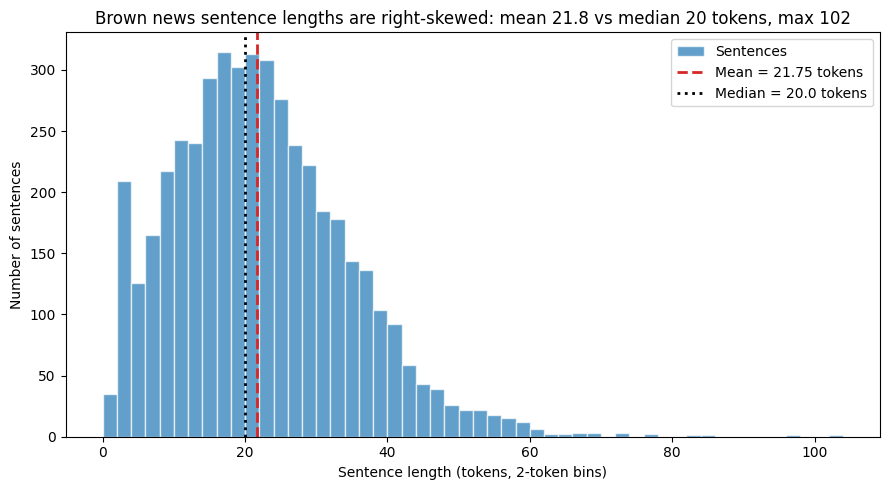

In [13]:
def plot_sent_length_hist(lengths, category_name, bin_width=2, figsize=(9, 5)):
    """Plot a histogram of sentence lengths with mean and median marked.

    Args:
        lengths (np.ndarray): Array of sentence lengths.
        category_name (str): Corpus category label for the title.
        bin_width (int): Width of each histogram bin, in tokens.
        figsize (tuple[float, float]): Figure size in inches.

    Returns:
        tuple: (fig, ax) matplotlib figure and axes.
    """
    lengths = np.asarray(lengths)
    require_non_empty(lengths, "lengths")
    if np.any(lengths < 0):
        raise ValueError("Sentence lengths cannot be negative.")
    if bin_width <= 0:
        raise ValueError(f"bin_width must be positive, got {bin_width}.")

    mean_length = float(lengths.mean())
    median_length = float(np.median(lengths))

    # Integer-aligned bin edges so each bar covers exactly bin_width token counts.
    bin_edges = np.arange(0, lengths.max() + bin_width + 1, bin_width)

    fig, ax = plt.subplots(figsize=figsize)
    ax.hist(lengths, bins=bin_edges, color="tab:blue", alpha=0.7, edgecolor="white",
            label="Sentences")
    ax.axvline(mean_length, color="tab:red", linestyle="--", linewidth=2,
               label=f"Mean = {mean_length:.2f} tokens")
    ax.axvline(median_length, color="black", linestyle=":", linewidth=2,
               label=f"Median = {median_length:.1f} tokens")

    # State the finding the chart shows: mean above median signals a long right tail.
    skew_description = ("right-skewed" if mean_length > median_length
                        else "left-skewed" if mean_length < median_length
                        else "symmetric")
    ax.set_title(f"Brown {category_name} sentence lengths are {skew_description}: "
                 f"mean {mean_length:.1f} vs median {median_length:.0f} tokens, "
                 f"max {int(lengths.max())}")
    ax.set_xlabel(f"Sentence length (tokens, {bin_width}-token bins)")
    ax.set_ylabel("Number of sentences")
    ax.legend()
    fig.tight_layout()
    return fig, ax

fig_sent, ax_sent = plot_sent_length_hist(sent_lengths_news, CORPUS_CATEGORY_A)
plt.show()

### 3.3 — Hapax legomena and vocabulary richness

In [14]:
from collections import Counter


def compute_vocab_richness(fdist):
    """Compute vocabulary richness statistics from a frequency distribution.

    Args:
        fdist (nltk.FreqDist): A frequency distribution over tokens.

    Returns:
        dict with keys:
            'vocab_size'    (int)   — number of unique types
            'hapax_count'   (int)   — number of types appearing exactly once
            'hapax_frac'    (float) — hapax_count / vocab_size, rounded to 4 dp
            'dis_count'     (int)   — types appearing exactly twice (dis legomena)
            'top_token'     (str)   — the most frequent token
            'top_freq'      (int)   — frequency of the most frequent token
    """
    require_non_empty(fdist, "fdist")
    vocab_size = len(fdist)
    # Frequency of frequencies: maps a count c to how many types occur c times,
    # giving hapax (c = 1) and dis legomena (c = 2) from a single pass.
    types_per_count = Counter(fdist.values())
    hapax_count = types_per_count[1]
    top_token, top_freq = fdist.most_common(1)[0]
    # Cast to native Python types so the autograder sees int/float/str, not numpy scalars.
    return {
        "vocab_size": int(vocab_size),
        "hapax_count": int(hapax_count),
        "hapax_frac": round(float(hapax_count / vocab_size), 4),
        "dis_count": int(types_per_count[2]),
        "top_token": str(top_token),
        "top_freq": int(top_freq),
    }

richness_news = compute_vocab_richness(fdist_news)

print("Vocabulary richness — news corpus:")
for k, v in richness_news.items():
    print(f"  {k}: {v}")

Vocabulary richness — news corpus:
  vocab_size: 13112
  hapax_count: 6834
  hapax_frac: 0.5212
  dis_count: 2061
  top_token: the
  top_freq: 6386


### 3.4 — Tokenization challenges

Standard tokenizers make assumptions that break down on real text. The cells below give you four short strings that expose common failure modes. For each one:

1. Run NLTK's `word_tokenize` on the string
2. Inspect the output
3. In the markdown cell below, identify what went wrong and name the linguistic phenomenon that caused it

These are `[RUN]` cells — no code to write, just run them and answer in the markdown cells.

In [15]:
# Tokenization challenge 1: Contractions and possessives
text_1 = "The patient's Dr. Smith couldn't make it to St. Mary's Hospital."
tokens_1 = word_tokenize(text_1)
print(f"Input:  {text_1}")
print(f"Tokens: {tokens_1}")
print(f"Count:  {len(tokens_1)} tokens")

Input:  The patient's Dr. Smith couldn't make it to St. Mary's Hospital.
Tokens: ['The', 'patient', "'s", 'Dr.', 'Smith', 'could', "n't", 'make', 'it', 'to', 'St.', 'Mary', "'s", 'Hospital', '.']
Count:  15 tokens


**What happened? What linguistic phenomenon caused this?** The tokenizer produced `['The', 'patient', "'s", 'Dr.', 'Smith', 'could', "n't", 'make', 'it', 'to', 'St.', 'Mary', "'s", 'Hospital', '.']` (15 tokens), following Penn Treebank clitic-splitting conventions: the possessive clitic was separated from its host (`'patient', "'s"` and `'Mary', "'s"`), and the negative contraction became `'could', "n't"`. The abbreviation periods in `'Dr.'` and `'St.'` stayed attached, and only the sentence-final period was split (`'Hospital', '.'`), so the segmentation is internally consistent, but it creates downstream problems. The token `"'s"` is the same string whether it marks possession (*patient's*) or contracts *is*/*has* (*it's*), so the POS tagger still has to disambiguate it. `"n't"` is not the word *not*, so a negation lexicon keyed on *not* misses it unless it is normalized, and the single named entity *St. Mary's Hospital* is spread over four tokens, one of which (`'St.'`) is itself ambiguous between *Saint* and *Street*. The convention also conflicts with the Brown tokenization used in Part 2, which keeps possessives attached (`fdist_news` contains types such as *president's* and *kennedy's*, and `"'s"` has a count of 0), so a vocabulary built from Brown counts would not match `word_tokenize` output. The phenomena are clitics (the possessive *'s* and the contraction *n't*) and abbreviation periods.

In [16]:
# Tokenization challenge 2: Hyphenation and compound words
text_2 = "The state-of-the-art system achieved a well-known, oft-cited result."
tokens_2 = word_tokenize(text_2)
print(f"Input:  {text_2}")
print(f"Tokens: {tokens_2}")
print(f"Count:  {len(tokens_2)} tokens")

Input:  The state-of-the-art system achieved a well-known, oft-cited result.
Tokens: ['The', 'state-of-the-art', 'system', 'achieved', 'a', 'well-known', ',', 'oft-cited', 'result', '.']
Count:  10 tokens


**What happened? What linguistic phenomenon caused this?** The tokenizer produced `['The', 'state-of-the-art', 'system', 'achieved', 'a', 'well-known', ',', 'oft-cited', 'result', '.']` (10 tokens): every hyphenated compound stayed a single token, and the comma was correctly split from `'well-known'`. For syntax this is defensible, since *state-of-the-art* functions as one prenominal adjective, but it is a problem for vocabulary and representation. Each compound becomes its own rare type that shares nothing with its parts: `'well-known'` is unrelated to *known*, and `'state-of-the-art'` is unrelated to the noun phrase *the state of the art*. Neither `'state-of-the-art'` nor `'well-known'` occurs in the Brown news vocabulary (both have a count of 0 in `fdist_news`), so a word-level vocabulary from Part 2 would map them to <UNK>, and 635 of the 6,834 news hapaxes contain a hyphen, so hyphenation is a measurable source of the sparse tail. The phenomenon is productive hyphenated compounding (phrasal compound modifiers), a word-formation process that punctuation-based tokenization cannot decompose; the alternative of splitting on hyphens would instead break a single modifier into parts that the parser has to reassemble.

In [17]:
# Tokenization challenge 3: Numbers, currency, and special notation
text_3 = "The $2.5M deal closed on 03/15/2024, with a 7.5% interest rate."
tokens_3 = word_tokenize(text_3)
print(f"Input:  {text_3}")
print(f"Tokens: {tokens_3}")
print(f"Count:  {len(tokens_3)} tokens")

Input:  The $2.5M deal closed on 03/15/2024, with a 7.5% interest rate.
Tokens: ['The', '$', '2.5M', 'deal', 'closed', 'on', '03/15/2024', ',', 'with', 'a', '7.5', '%', 'interest', 'rate', '.']
Count:  15 tokens


**What happened? What linguistic phenomenon caused this?** The tokenizer produced `['The', '$', '2.5M', 'deal', 'closed', 'on', '03/15/2024', ',', 'with', 'a', '7.5', '%', 'interest', 'rate', '.']` (15 tokens). It handled the decimal points correctly (neither `2.5` nor `7.5` was split at the period) and split off `'$'` as Penn Treebank prescribes, but it treated unit-bearing numerals inconsistently: the magnitude suffix stayed fused in `'2.5M'`, while the percent sign was split into `'7.5', '%'`. As a result, the single monetary quantity *$2.5 million* is spread across `'$'` and `'2.5M'`, with *M* left unnormalized, and the date `'03/15/2024'` is one opaque token whose month-first reading is recoverable only because 15 cannot be a month (*03/04/2024* would be ambiguous between US and European conventions). Because every distinct amount, date, and rate becomes a separate type, numbers make the vocabulary open-ended (576 of the 6,834 news hapaxes contain a digit). Pipelines therefore normalize them to placeholders or spelled-out forms, and NER has to reassemble MONEY, DATE, and PERCENT spans across tokens. The phenomenon is numeric and currency/date/percent expressions, the "non-standard words" that require text normalization rather than punctuation-based splitting.

In [18]:
# Tokenization challenge 4: Sentence boundary detection on real news text
text_4 = "The U.S. economy grew 3.2 pct. in Q3. Dr. J. Evans said it was unexpected."
sentences_4 = sent_tokenize(text_4)
print(f"Input: {text_4}")
print(f"\nDetected sentences ({len(sentences_4)} total):")
for i, s in enumerate(sentences_4, 1):
    print(f"  {i}: {s}")

Input: The U.S. economy grew 3.2 pct. in Q3. Dr. J. Evans said it was unexpected.

Detected sentences (3 total):
  1: The U.S. economy grew 3.2 pct.
  2: in Q3.
  3: Dr. J. Evans said it was unexpected.


**What happened? What linguistic phenomenon caused this?** `sent_tokenize` returned three sentences, `The U.S. economy grew 3.2 pct.`, `in Q3.`, and `Dr. J. Evans said it was unexpected.`, where the correct segmentation has two. Punkt handled most of the periods correctly: it did not break after `U.S.` or `Dr.` (both are in its pretrained English abbreviation list), after the initial `J.`, or inside the decimal `3.2`, and it correctly ended the first sentence at `Q3.`. The error is a false boundary after `pct.`: this news-style abbreviation for *percent* is not in the pretrained model's abbreviation set, so Punkt treated the period as sentence-final, even though the next word, *in*, is lowercase. The result is a truncated first sentence and a verbless fragment, *in Q3.*, whose prepositional phrase has nothing to attach to, so a parser receives two ill-formed inputs. Because `word_tokenize` runs sentence splitting first, the same error appears at the word level (`'3.2', 'pct', '.', 'in', 'Q3', '.'`). The phenomenon is sentence boundary detection, specifically disambiguating abbreviation periods from sentence-final periods; since Punkt is unsupervised, adding *pct* to its abbreviation set or retraining it on in-domain news text would fix this case.

### 3.5 — Produce named output variables

The autograder checks the named variables below. Make sure they are defined and consistent with your analysis above.

In [19]:
# Sentence length statistics (already computed above — assign here for the autograder)
news_sent_mean   = sent_mean
news_sent_median = sent_median
news_sent_std    = sent_std
news_sent_max    = sent_max

# Vocabulary richness (already computed — extract fields here)
news_vocab_size  = richness_news['vocab_size']
news_hapax_count = richness_news['hapax_count']
news_hapax_frac  = richness_news['hapax_frac']

# Coverage: number of word types needed for 90% token coverage (news)
news_coverage_90 = coverage_news[0.90]

# TTR
news_ttr         = ttr_news
fiction_ttr      = ttr_fiction

print("Autograder variables:")
print(f"  news_sent_mean:    {news_sent_mean}")
print(f"  news_sent_median:  {news_sent_median}")
print(f"  news_sent_std:     {news_sent_std}")
print(f"  news_sent_max:     {news_sent_max}")
print(f"  news_vocab_size:   {news_vocab_size}")
print(f"  news_hapax_count:  {news_hapax_count}")
print(f"  news_hapax_frac:   {news_hapax_frac}")
print(f"  news_coverage_90:  {news_coverage_90}")
print(f"  news_ttr:          {news_ttr}")
print(f"  fiction_ttr:       {fiction_ttr}")

Autograder variables:
  news_sent_mean:    21.75
  news_sent_median:  20.0
  news_sent_std:     12.27
  news_sent_max:     102
  news_vocab_size:   13112
  news_hapax_count:  6834
  news_hapax_frac:   0.5212
  news_coverage_90:  4668
  news_ttr:          0.1304
  fiction_ttr:       0.1267


### 3.6 — Supporting calculations for the written answers

The Part 2.7 and Part 3.4 answers cite a few figures that are not printed by the cells above. This cell computes each of them so every number in the written analysis is reproducible from visible output.

In [20]:
def oov_rate(vocab, tokens):
    """Return the fraction of tokens whose type is not in a vocabulary.

    Args:
        vocab (set[str]): The in-vocabulary word types.
        tokens (list[str]): Tokens to check against the vocabulary.

    Returns:
        float: Out-of-vocabulary token rate in [0, 1].

    Raises:
        ValueError: If tokens is empty.
    """
    if not tokens:
        raise ValueError("tokens must be a non-empty list")
    return sum(1 for tok in tokens if tok not in vocab) / len(tokens)


# Question A — vocabulary of every type seen at least twice (i.e. drop the hapaxes)
min_count = 2
vocab_min2 = {w for w, c in fdist_news.items() if c >= min_count}
print(f"Types with count >= {min_count}: {len(vocab_min2):,}")
print(f"  News token coverage: {1 - oov_rate(vocab_min2, tokens_news):.1%}  "
      f"(<UNK> rate {oov_rate(vocab_min2, tokens_news):.1%})")

# Question B — TTR at equal corpus length, and cross-domain OOV rate
ttr_news_matched = compute_ttr(tokens_news[:len(tokens_fiction)])
print(f"\nNews TTR truncated to fiction length ({len(tokens_fiction):,} tokens): {ttr_news_matched}")

vocab_news_95 = {w for w, _ in fdist_news.most_common(coverage_news[0.95])}
print(f"Top {coverage_news[0.95]:,} news types (95% threshold):")
print(f"  OOV rate on news:    {oov_rate(vocab_news_95, tokens_news):.1%}")
print(f"  OOV rate on fiction: {oov_rate(vocab_news_95, tokens_fiction):.1%}")

# Part 3.4 — composition of the hapax tail and Brown's possessive convention
news_hapaxes = fdist_news.hapaxes()
print(f"\nNews hapaxes containing a hyphen: {sum('-' in w for w in news_hapaxes):,} of {len(news_hapaxes):,}")
print(f"News hapaxes containing a digit:  {sum(any(ch.isdigit() for ch in w) for w in news_hapaxes):,} of {len(news_hapaxes):,}")
possessive_clitic, attached_example = "'s", "president's"
print(f"Count of the token {possessive_clitic!r} in Brown news: {fdist_news[possessive_clitic]}  "
      f"(vs. {attached_example!r} = {fdist_news[attached_example]})")
for attached in ("kennedy's",):
    print(f"Count of {attached!r} in Brown news: {fdist_news[attached]}")
for compound in ("state-of-the-art", "well-known"):
    print(f"Count of '{compound}' in Brown news: {fdist_news[compound]}")

# Part 3.4, challenge 4 — word_tokenize inherits the sentence splitter's error
print(f"\nword_tokenize(text_4): {word_tokenize(text_4)}")


Types with count >= 2: 6,278
  News token coverage: 93.2%  (<UNK> rate 6.8%)

News TTR truncated to fiction length (68,488 tokens): 0.1509
Top 8,085 news types (95% threshold):
  OOV rate on news:    5.0%
  OOV rate on fiction: 14.7%

News hapaxes containing a hyphen: 635 of 6,834
News hapaxes containing a digit:  576 of 6,834
Count of the token "'s" in Brown news: 0  (vs. "president's" = 12)
Count of "kennedy's" in Brown news: 11
Count of 'state-of-the-art' in Brown news: 0
Count of 'well-known' in Brown news: 0

word_tokenize(text_4): ['The', 'U.S.', 'economy', 'grew', '3.2', 'pct', '.', 'in', 'Q3', '.', 'Dr.', 'J.', 'Evans', 'said', 'it', 'was', 'unexpected', '.']


---

## Part 4 — Corpus Loading and Inspection with pandas

*This part covers a Canvas brief item that the scaffold does not: loading the corpus into a pandas DataFrame and inspecting its structure at the document level.*

Parts 2 and 3 treated each category as one long token stream. Here I keep document boundaries, with one row per Brown file (`fileid`), so I can check data integrity (shape, dtypes, missing values) and see how document length is distributed. I include both categories used in Part 2 so the two domains can be compared at the document level.

The cell below adds the imports Parts 4–8 need that the setup cell does not provide.

In [21]:
# Extra imports for Parts 4-8 (the setup cell does not import these).
import re
import random
from collections import Counter

from nltk.corpus import stopwords

### 4.1 — Build a document-level DataFrame

In [22]:
def build_document_frame(corpus, categories):
    """Build a DataFrame with one row per corpus document.

    Each document's ``text`` is its tokens joined by single spaces. I keep
    Brown's original tokenization instead of detokenizing, so the column is a
    lossless view of the tokens: ``len(text.split()) == n_tokens``. Part 7
    relies on this when it writes regular expressions against the raw text.

    Args:
        corpus: An NLTK categorized corpus reader exposing ``categories()``,
            ``fileids(categories=...)`` and ``sents(fileids=...)``.
        categories (Iterable[str]): Category names to include, e.g. ``['news']``.

    Returns:
        pd.DataFrame: Columns ``fileid`` (str), ``category`` (str), ``text``
            (str), ``n_tokens`` (int), ``n_sentences`` (int) and
            ``mean_sent_len`` (float, tokens per sentence).

    Raises:
        ValueError: If ``categories`` is empty or contains an unknown category.
    """
    categories = list(categories)
    if not categories:
        raise ValueError("categories must contain at least one category name.")
    unknown = sorted(set(categories) - set(corpus.categories()))
    if unknown:
        raise ValueError(f"Unknown categories {unknown}. Valid: {corpus.categories()}")

    rows = []
    for category in categories:
        for fileid in corpus.fileids(categories=category):
            sents = corpus.sents(fileids=fileid)
            tokens = [token for sent in sents for token in sent]
            rows.append({
                "fileid": fileid,
                "category": category,
                "text": " ".join(tokens),
                "n_tokens": len(tokens),
                "n_sentences": len(sents),
            })

    df = pd.DataFrame(rows)
    df["mean_sent_len"] = (df["n_tokens"] / df["n_sentences"]).round(2)
    return df


docs_df = build_document_frame(brown, [CORPUS_CATEGORY_A, CORPUS_CATEGORY_B])

# Integrity check: the document view must agree with the Part 2 token stream.
news_mask = docs_df["category"] == CORPUS_CATEGORY_A
assert docs_df.loc[news_mask, "n_tokens"].sum() == len(tokens_news), \
    "Document token counts do not add up to len(tokens_news)."
assert (docs_df["text"].str.split().str.len() == docs_df["n_tokens"]).all(), \
    "Space-joined text is not a lossless view of the tokens."

print(f"df.shape: {docs_df.shape}\n")
print("df.dtypes:")
print(docs_df.dtypes.to_string(), "\n")
print("df.isna().sum():")
print(docs_df.isna().sum().to_string())
display(docs_df.head())

df.shape: (73, 6)

df.dtypes:
fileid            object
category          object
text              object
n_tokens           int64
n_sentences        int64
mean_sent_len    float64 

df.isna().sum():
fileid           0
category         0
text             0
n_tokens         0
n_sentences      0
mean_sent_len    0


,fileid,category,text,n_tokens,n_sentences,mean_sent_len
0,ca01,news,The Fulton County Grand Jury said Friday an in...,2242,98,22.88
1,ca02,news,"Austin , Texas -- Committee approval of Gov. P...",2277,98,23.23
2,ca03,news,Several defendants in the Summerdale police bu...,2275,112,20.31
3,ca04,news,Oslo The most positive element to emerge from ...,2217,88,25.19
4,ca05,news,East Providence should organize its civil defe...,2244,84,26.71


### 4.2 — Document-length summary

In [23]:
def summarize_documents(df, group_col="category", length_col="n_tokens"):
    """Summarize document counts and length statistics per group.

    Args:
        df (pd.DataFrame): Document-level frame, e.g. from ``build_document_frame``.
        group_col (str): Column to group by.
        length_col (str): Numeric column holding document length.

    Returns:
        pd.DataFrame: One row per group with ``n_documents``, ``total``,
            ``mean``, ``median``, ``std``, ``min`` and ``max`` of ``length_col``.

    Raises:
        KeyError: If either column is missing from ``df``.
    """
    missing = {group_col, length_col} - set(df.columns)
    if missing:
        raise KeyError(f"Columns not found in DataFrame: {sorted(missing)}")
    return (df.groupby(group_col)[length_col]
              .agg(n_documents="count", total="sum", mean="mean",
                   median="median", std="std", min="min", max="max")
              .round(1))


length_summary = summarize_documents(docs_df)
display(length_summary)

news_docs = docs_df[news_mask]
print(f"News: {len(news_docs)} documents, {news_docs['n_tokens'].sum():,} tokens, "
      f"{news_docs['n_sentences'].sum():,} sentences")
print(f"News document length: mean {news_docs['n_tokens'].mean():,.1f}, "
      f"median {news_docs['n_tokens'].median():,.1f} tokens "
      f"(coefficient of variation {news_docs['n_tokens'].std() / news_docs['n_tokens'].mean():.3f})")
print(f"News mean sentence length per document ranges from "
      f"{news_docs['mean_sent_len'].min()} to {news_docs['mean_sent_len'].max()} tokens")

,n_documents,total,mean,median,std,min,max
category,,,,,,,
fiction,29,68488,2361.7,2364.0,72.8,2218,2527
news,44,100554,2285.3,2280.0,50.1,2187,2452


News: 44 documents, 100,554 tokens, 4,623 sentences
News document length: mean 2,285.3, median 2,280.0 tokens (coefficient of variation 0.022)
News mean sentence length per document ranges from 17.51 to 29.96 tokens


**Interpretation.** The DataFrame has 73 rows (44 news and 29 fiction documents) and 6 columns, with no missing values. The dtypes are as intended: `object` for the string columns, `int64` for the counts, and `float64` for the mean sentence length. The two integrity assertions pass, so the 44 news documents add up to exactly the 100,554 tokens of `tokens_news`, and the space-joined `text` column round-trips to the original tokens. News documents average 2,285.3 tokens (median 2,280.0, range 2,187–2,452). Their coefficient of variation is only 0.022, which reflects how the corpus was built, not a property of newspaper writing: Brown consists of samples of roughly 2,000 words each. The count exceeds 2,000 because Brown counts punctuation as tokens. Punctuation is 11.9% of news tokens (Part 5), and 2,285.3 × 0.881 ≈ 2,013 word tokens per document, which matches the design. Two consequences follow. Document length carries no information in this corpus and should not be used as a feature. And with only 44 news documents, any document-level experiment (classification, train/test splits) would be very small. The variation that does matter is stylistic: mean sentence length ranges from 17.51 to 29.96 tokens across news files, so some articles are written in consistently longer sentences than others. The sentence-level long right tail itself is shown by the Part 3 histogram.

---

## Part 5 — Top-20 Words, Hapax Legomena, and Preprocessing Needs

*This part covers the Canvas brief item asking for the 20 most frequent words, the hapax legomena, and what the frequency distribution implies for preprocessing.*

I compare the raw top 20 against the top 20 after removing NLTK's English stopwords and pure-punctuation tokens. Then I look at the other end of the Zipf curve, the hapax tail, and break it down by orthographic shape to see which preprocessing steps would actually shrink it.

### 5.1 — Top-20 tokens, raw and filtered

In [24]:
STOPWORDS_EN = frozenset(stopwords.words("english"))
TOP_N = 20


def is_punctuation(token):
    """Return True if a token contains no letters or digits.

    Args:
        token (str): A single token, e.g. ``','``, ``'``'``, ``'--'``.

    Returns:
        bool: True for pure-punctuation tokens.
    """
    return not any(ch.isalnum() for ch in token)


def filter_fdist(fdist, drop_tokens=frozenset(), drop_punctuation=True):
    """Return a new FreqDist without the given tokens and, optionally, punctuation.

    The input distribution is left unchanged.

    Args:
        fdist (nltk.FreqDist): Source frequency distribution.
        drop_tokens (Collection[str]): Tokens to remove (e.g. a stopword set).
        drop_punctuation (bool): If True, also remove pure-punctuation tokens.

    Returns:
        nltk.FreqDist: The filtered distribution.
    """
    return FreqDist({
        token: count for token, count in fdist.items()
        if token not in drop_tokens and not (drop_punctuation and is_punctuation(token))
    })


def top_n_table(fdist, n=TOP_N, total_tokens=None):
    """Tabulate the n most frequent tokens with their share of the corpus.

    Args:
        fdist (nltk.FreqDist): Frequency distribution to rank.
        n (int): Number of rows to return (must be >= 1).
        total_tokens (int | None): Denominator for the percentages. Defaults
            to ``fdist.N()``; pass the unfiltered total to express a filtered
            table as a share of the whole corpus.

    Returns:
        pd.DataFrame: Indexed by rank (1..n), with columns ``token``,
            ``count``, ``pct`` (share of tokens) and ``cum_pct`` (cumulative).

    Raises:
        ValueError: If ``n < 1`` or the distribution/denominator is empty.
    """
    if n < 1:
        raise ValueError(f"n must be >= 1, got {n}.")
    total = fdist.N() if total_tokens is None else total_tokens
    if total <= 0:
        raise ValueError("Cannot compute shares for an empty distribution.")
    table = pd.DataFrame(fdist.most_common(n), columns=["token", "count"])
    # Cumulate raw counts, then convert; cumulating rounded percentages would drift.
    table["pct"] = (100 * table["count"] / total).round(2)
    table["cum_pct"] = (100 * table["count"].cumsum() / total).round(2)
    table.index = pd.RangeIndex(1, len(table) + 1, name="rank")
    return table


fdist_news_content = filter_fdist(fdist_news, drop_tokens=STOPWORDS_EN)
top_raw_news = top_n_table(fdist_news)
top_content_news = top_n_table(fdist_news_content, total_tokens=fdist_news.N())

display(pd.concat({"All tokens": top_raw_news,
                   "Stopwords and punctuation removed": top_content_news}, axis=1))

All tokens                     Stopwords and punctuation removed        \
          token count   pct cum_pct                             token count   
rank                                                                          
1           the  6386  6.35    6.35                              said   406   
2             ,  5188  5.16   11.51                              mrs.   253   
3             .  4030  4.01   15.52                             would   246   
4            of  2861  2.85   18.36                               new   241   
5           and  2186  2.17   20.54                               one   213   
6            to  2144  2.13   22.67                              last   177   
7             a  2130  2.12   24.79                               two   174   
8            in  2020  2.01   26.80                               mr.   170   
9           for   969  0.96   27.76                             first   158   
10         that   829  0.82   28.58                             state   153   
11           is   733  0.73   29.31                              year   142   
12           ``   732  0.73   30.04                         president   142   
13          was   717  0.71   30.75                              home   132   
14           ''   702  0.70   31.45                              also   129   
15           on   691  0.69   32.14                              made   107   
16           he   642  0.64   32.78                              time   103   
17           at   636  0.63   33.41                             years   102   
18         with   567  0.56   33.97                             three   101   
19           be   526  0.52   34.50                             house    97   
20           as   517  0.51   35.01                              week    94   

                    
       pct cum_pct  
rank                
1     0.40    0.40  
2     0.25    0.66  
3     0.24    0.90  
4     0.24    1.14  
5     0.21    1.35  
6     0.18    1.53  
7     0.17    1.70  
8     0.17    1.87  
9     0.16    2.03  
10    0.15    2.18  
11    0.14    2.32  
12    0.14    2.46  
13    0.13    2.59  
14    0.13    2.72  
15    0.11    2.83  
16    0.10    2.93  
17    0.10    3.03  
18    0.10    3.13  
19    0.10    3.23  
20    0.09    3.32

In [25]:
def token_class_shares(fdist, stopword_set):
    """Split a corpus's tokens into punctuation, stopword, and content classes.

    Args:
        fdist (nltk.FreqDist): Frequency distribution over tokens.
        stopword_set (Collection[str]): Tokens counted as stopwords.

    Returns:
        dict[str, float]: Percentage of all tokens (by count) in each class.
    """
    counts = Counter()
    for token, count in fdist.items():
        if is_punctuation(token):
            counts["punctuation"] += count
        elif token in stopword_set:
            counts["stopword"] += count
        else:
            counts["content"] += count
    return {cls: round(100 * counts[cls] / fdist.N(), 2)
            for cls in ("punctuation", "stopword", "content")}


n_punct_top = int(top_raw_news["token"].map(is_punctuation).sum())
n_stop_top = int(top_raw_news["token"].isin(STOPWORDS_EN).sum())
news_class_shares = token_class_shares(fdist_news, STOPWORDS_EN)

print(f"Vocabulary size (types):       {richness_news['vocab_size']:,}")
print(f"Hapax legomena (freq = 1):     {richness_news['hapax_count']:,} "
      f"({richness_news['hapax_frac']:.1%} of types)")
print(f"Dis legomena (freq = 2):       {richness_news['dis_count']:,}")
print(f"Top-{TOP_N} raw tokens: {n_punct_top} punctuation + {n_stop_top} stopwords "
      f"= {top_raw_news['cum_pct'].iloc[-1]}% of all tokens")
print(f"Top-{TOP_N} content tokens cover only {top_content_news['cum_pct'].iloc[-1]}% of all tokens")
print(f"Token classes across the whole news corpus (% of tokens): {news_class_shares}")

Vocabulary size (types):       13,112
Hapax legomena (freq = 1):     6,834 (52.1% of types)
Dis legomena (freq = 2):       2,061
Top-20 raw tokens: 4 punctuation + 16 stopwords = 35.01% of all tokens
Top-20 content tokens cover only 3.32% of all tokens
Token classes across the whole news corpus (% of tokens): {'punctuation': 11.9, 'stopword': 36.7, 'content': 51.4}


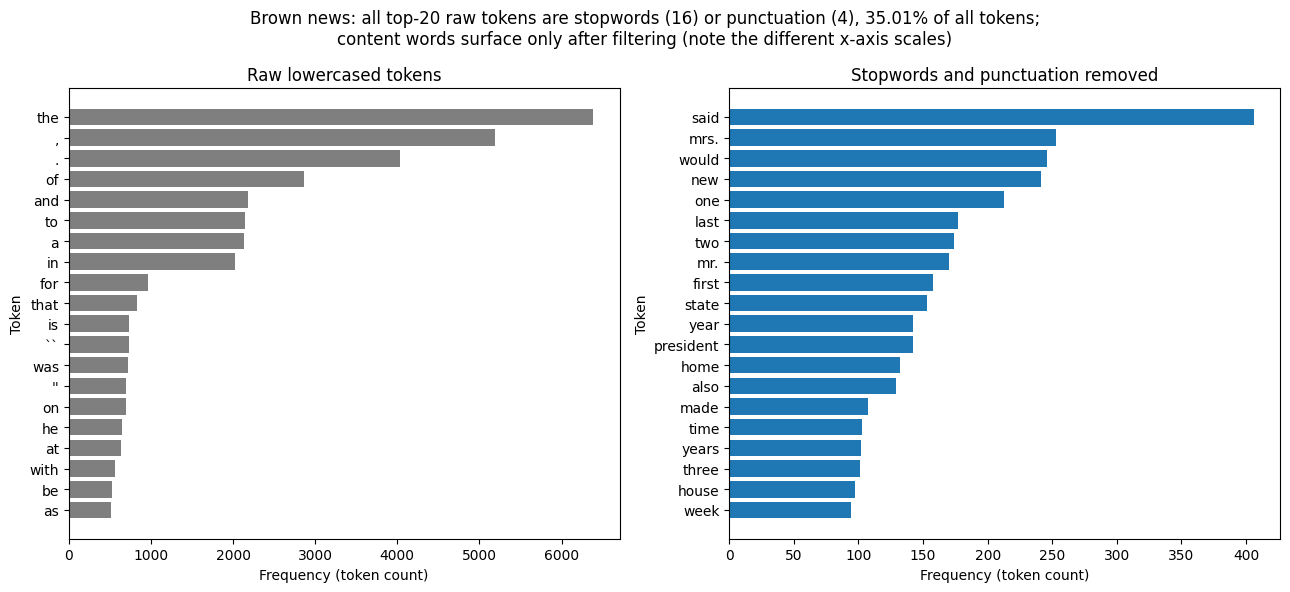

In [26]:
def plot_top_n_comparison(table_a, table_b, label_a, label_b, title):
    """Draw two horizontal bar charts of top-n token counts side by side.

    Args:
        table_a (pd.DataFrame): Output of ``top_n_table`` for the left panel.
        table_b (pd.DataFrame): Output of ``top_n_table`` for the right panel.
        label_a (str): Subplot title for the left panel.
        label_b (str): Subplot title for the right panel.
        title (str): Figure title (should state the finding).

    Returns:
        tuple: (fig, axes) matplotlib figure and array of two axes.
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    for ax, table, label, color in zip(axes, (table_a, table_b), (label_a, label_b),
                                       ("tab:gray", "tab:blue")):
        # Reverse so rank 1 is drawn at the top of the horizontal bar chart.
        ax.barh(table["token"][::-1], table["count"][::-1], color=color)
        ax.set_title(label)
        ax.set_xlabel("Frequency (token count)")
        ax.set_ylabel("Token")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    return fig, axes


n_function_top = n_punct_top + n_stop_top
head_label = "all" if n_function_top == TOP_N else f"{n_function_top} of the"
fig_top, axes_top = plot_top_n_comparison(
    top_raw_news, top_content_news,
    "Raw lowercased tokens", "Stopwords and punctuation removed",
    f"Brown news: {head_label} top-{TOP_N} raw tokens are stopwords ({n_stop_top}) or punctuation ({n_punct_top}), "
    f"{top_raw_news['cum_pct'].iloc[-1]}% of all tokens;\ncontent words surface only after filtering "
    f"(note the different x-axis scales)")
plt.show()

### 5.2 — What the hapax tail is made of

The hapax count alone does not say which preprocessing steps would help. The cell below classifies every hapax by orthographic shape and measures how much lowercasing (already applied in Part 2) collapsed the vocabulary.

In [27]:
# Ordered (label, test) pairs: the first matching test wins, so the more
# specific shapes (digits, hyphens, apostrophes) are checked before "alphabetic".
TOKEN_SHAPES = (
    ("contains digit", lambda t: any(ch.isdigit() for ch in t)),
    ("hyphenated", lambda t: "-" in t.strip("-")),
    ("apostrophe", lambda t: "'" in t),
    ("alphabetic", str.isalpha),
)


def token_shape(token, shapes=TOKEN_SHAPES):
    """Assign a token to the first orthographic shape class whose test it passes.

    Args:
        token (str): Token to classify.
        shapes (Sequence[tuple[str, Callable[[str], bool]]]): Ordered
            (label, predicate) pairs.

    Returns:
        str: The matching label, or ``'other'`` if no test passes.
    """
    for label, test in shapes:
        if test(token):
            return label
    return "other"


def shape_breakdown(tokens):
    """Count tokens per orthographic shape class.

    Args:
        tokens (Iterable[str]): Tokens (e.g. the hapax legomena) to classify.

    Returns:
        pd.DataFrame: Columns ``count`` and ``pct``, sorted by count.

    Raises:
        ValueError: If ``tokens`` is empty.
    """
    counts = Counter(token_shape(t) for t in tokens)
    if not counts:
        raise ValueError("No tokens to classify.")
    table = pd.DataFrame.from_dict(counts, orient="index", columns=["count"])
    table["pct"] = (100 * table["count"] / table["count"].sum()).round(1)
    return table.sort_values("count", ascending=False)


news_hapaxes = fdist_news.hapaxes()
hapax_shapes = shape_breakdown(news_hapaxes)
print(f"Shape of the {len(news_hapaxes):,} news hapax legomena:")
display(hapax_shapes)

rng = random.Random(0)  # fixed seed so the printed sample is reproducible
for label in hapax_shapes.index:
    members = sorted(t for t in news_hapaxes if token_shape(t) == label)
    print(f"  {label:<15} e.g. {rng.sample(members, min(6, len(members)))}")

cased_vocab_news = len(set(brown.words(categories=CORPUS_CATEGORY_A)))
digit_types = sum(1 for t in fdist_news if any(ch.isdigit() for ch in t))
print(f"\nCased vocabulary: {cased_vocab_news:,} types; lowercased: {richness_news['vocab_size']:,} "
      f"(lowercasing merged {cased_vocab_news - richness_news['vocab_size']:,} types, "
      f"{1 - richness_news['vocab_size'] / cased_vocab_news:.1%})")
print(f"Types containing a digit: {digit_types:,} ({digit_types / richness_news['vocab_size']:.1%} of the vocabulary)")

Shape of the 6,834 news hapax legomena:


,count,pct
alphabetic,5417,79.3
contains digit,576,8.4
hyphenated,471,6.9
apostrophe,322,4.7
other,48,0.7


  alphabetic      e.g. ['modernized', 'overly', 'backbone', 'govern', 'sadism', 'religion']
  contains digit  e.g. ['38-point', '2100', '6.5', '3-inch', '173', '7-9']
  hyphenated      e.g. ['cross-examination', 'fund-raisers', 'super-secret', 'camping-out', 'r-cape', 'three-day']
  apostrophe      e.g. ["guide's", "steelmakers'", "war's", "cuba's", "krogers'", "car's"]
  other           e.g. ['vs.', 'cir.', 'tenn.', 'lt.', 'nev.', 'q.']

Cased vocabulary: 14,394 types; lowercased: 13,112 (lowercasing merged 1,282 types, 8.9%)
Types containing a digit: 792 (6.0% of the vocabulary)


**Discussion: what the distribution says about preprocessing.**

*The head is function words and punctuation.* All 20 of the most frequent news tokens are stopwords (16) or punctuation (4: `,` `.` ` `` ` `''`), and together they account for 35.01% of all tokens. *the* alone is 6.35%. Across the whole corpus, stopwords make up 36.7% of tokens and punctuation 11.9%, so barely half the tokens (51.4%) are content-bearing. After filtering, the top 20 content tokens cover only 3.32% of the corpus. This is Zipf's law from Part 2 seen from the other side: the few highest-ranked types are grammatical, and topical vocabulary is spread thinly over thousands of types. For bag-of-words or TF-IDF models (J&M SLP3, chapters on text classification and vector semantics), I would remove or down-weight these tokens because they carry little topical signal. For language modeling, POS tagging, or parsing I would keep them, because function words and quotation marks carry the syntax (and here, reported speech).

*The filtered list exposes normalization issues.* The filtered top 20 is itself informative. *said* (406) is newswire's reporting verb. *mrs.* (253) and *mr.* (170) are abbreviations whose periods a sentence splitter must not treat as boundaries (the same failure as Part 3.4). *one*, *two*, *three*, and *first* are numerals that a number-normalization step would merge. *would* survives because NLTK's list happens to omit it, while *will* is on it, which shows that stopword lists are arbitrary and should be chosen per task. Brown also marks quotations with two different tokens (` `` ` and `''`, 732 and 702 occurrences), which should be mapped to a single quote symbol.

*The tail drives sparsity.* There are 6,834 hapax legomena, 52.1% of the 13,112 types, plus 2,061 dis legomena. So 67.8% of the vocabulary occurs at most twice, and any closed vocabulary will send much of it to `<UNK>`. The shape breakdown shows how much normalization can fix. Types containing a digit make up 8.4% of hapaxes (576, such as *38-point*, *2100*, *6.5*), and replacing numbers with typed placeholders (Part 7) would collapse them. Hyphenated compounds (6.9%) and possessive clitics (4.7%, such as *war's*, *car's*) would mostly disappear with Penn-Treebank-style clitic splitting and hyphen handling. But 79.3% of hapaxes are ordinary alphabetic words (*modernized*, *backbone*, *sadism*). No normalization removes these, which is the argument for subword tokenization such as BPE (J&M SLP3, tokenization chapter) over an ever-larger word vocabulary.

*Casing is a trade-off.* Lowercasing already merged 1,282 types (8.9% of the 14,394 cased types), a real reduction in sparsity. As Part 6 shows, though, it also merges distinct words (*Bill* the name and *bill* the legislation), so a case-sensitive task such as NER should keep case or add a capitalization feature.

---

## Part 6 — Ambiguity in Real Corpus Sentences

*This part covers the Canvas brief item asking for at least two lexical and one syntactic ambiguity example taken from the corpus itself, not from textbook sentences.*

Part 1 classified constructed examples. Here I look for the same phenomena in Brown news. Brown is POS-tagged, so for a lexical candidate I can show that one word form carries several tags. For syntactic candidates I can search for tag sequences that allow more than one parse (see the J&M SLP3 chapters on POS tagging, constituency parsing, and word senses). Every sentence quoted in the markdown is printed by the code and checked against the corpus in 6.5.

### 6.1 — Search utilities

In [28]:
BROWN_TAG_MODIFIERS = re.compile(r"-(?:TL|HL|NC)")  # title, headline, cited-word markers


def base_tag(tag):
    """Strip Brown's -TL/-HL/-NC modifiers so that e.g. 'NN-TL' compares equal to 'NN'.

    Args:
        tag (str): A Brown POS tag.

    Returns:
        str: The tag without context modifiers.
    """
    return BROWN_TAG_MODIFIERS.sub("", tag)


def load_tagged_sentences(corpus, category):
    """Load a category's tagged sentences, keeping the source fileid of each.

    Args:
        corpus: An NLTK tagged, categorized corpus reader (e.g. ``brown``).
        category (str): Category name.

    Returns:
        list[tuple[str, list[tuple[str, str]]]]: ``(fileid, [(word, tag), ...])`` pairs.

    Raises:
        ValueError: If ``category`` is not in the corpus.
    """
    if category not in corpus.categories():
        raise ValueError(f"Unknown category '{category}'. Valid: {corpus.categories()}")
    return [(fileid, sent)
            for fileid in corpus.fileids(categories=category)
            for sent in corpus.tagged_sents(fileids=fileid)]


def sentence_text(tagged_sent):
    """Join the words of a tagged sentence with single spaces (Brown tokenization).

    Args:
        tagged_sent (list[tuple[str, str]]): (word, tag) pairs for one sentence.

    Returns:
        str: The sentence's words separated by single spaces.
    """
    return " ".join(word for word, _ in tagged_sent)


def tag_profile(tagged_sents, words):
    """Tabulate how often each word form (case-insensitive) occurs with each base tag.

    Args:
        tagged_sents (list): Output of ``load_tagged_sentences``.
        words (Iterable[str]): Word forms to profile.

    Returns:
        pd.DataFrame: One row per word; columns are base tags (counts) plus
            ``n_tags`` (number of distinct tags), sorted by ``n_tags``.
    """
    # dict (not set) keeps the caller's word order, so the table is identical on every run
    profile = {w: Counter() for w in dict.fromkeys(w.lower() for w in words)}
    for _, sent in tagged_sents:
        for word, tag in sent:
            if word.lower() in profile:
                profile[word.lower()][base_tag(tag)] += 1
    table = pd.DataFrame(profile).T.fillna(0).astype(int)
    table["n_tags"] = (table > 0).sum(axis=1)
    return table.sort_values("n_tags", ascending=False, kind="stable")


def find_word_in_context(tagged_sents, target, tag_prefix=None, max_hits=5):
    """Print and return corpus sentences containing a target word form.

    The target is shown in the sentence as ``word/TAG`` so the evidence for
    the reading (the corpus annotators' POS tag) is visible next to it.

    Args:
        tagged_sents (list): Output of ``load_tagged_sentences``.
        target (str): Word form to find (case-insensitive).
        tag_prefix (str | None): If given, keep only hits whose base tag
            starts with this prefix (e.g. ``'NN'`` or ``'JJ'``).
        max_hits (int): Maximum number of hits to print (all are returned).

    Returns:
        list[dict]: One dict per hit with keys ``fileid``, ``tag``, ``sentence``.

    Raises:
        ValueError: If ``target`` is empty or ``max_hits < 1``.
    """
    if not target or not target.strip():
        raise ValueError("target must be a non-empty string.")
    if max_hits < 1:
        raise ValueError(f"max_hits must be >= 1, got {max_hits}.")
    target = target.lower()
    hits = []
    for fileid, sent in tagged_sents:
        for i, (word, tag) in enumerate(sent):
            if word.lower() == target and (tag_prefix is None or base_tag(tag).startswith(tag_prefix)):
                marked = [f"{w}/{t}" if j == i else w for j, (w, t) in enumerate(sent)]
                hits.append({"fileid": fileid, "tag": tag,
                             "sentence": sentence_text(sent), "marked": " ".join(marked)})
                break  # one hit per sentence is enough
    label = f"'{target}'" + (f" tagged {tag_prefix}*" if tag_prefix else "")
    print(f"{label}: {len(hits)} sentence(s); showing {min(max_hits, len(hits))}")
    for hit in hits[:max_hits]:
        print(f"  [{hit['fileid']}] {hit['marked']}")
    return hits


def find_tag_pattern(tagged_sents, pattern, max_hits=5):
    """Find token sequences that match a pattern of word forms and/or base tags.

    Each pattern slot is a set of alternatives; a token matches the slot if its
    lowercased word or its base tag is in the set. Words are lowercase and tags
    uppercase, so the two never collide. Example: ``[{'VB', 'VBD'}, {'AT'},
    {'NN'}, {'with'}]`` finds verb + determiner + noun + "with".

    Args:
        tagged_sents (list): Output of ``load_tagged_sentences``.
        pattern (Sequence[Collection[str]]): Non-empty list of slots.
        max_hits (int): Maximum number of hits to print (all are returned).

    Returns:
        list[dict]: One dict per match with keys ``fileid``, ``span``, ``sentence``.

    Raises:
        ValueError: If ``pattern`` is empty or contains an empty slot.
    """
    if not pattern or any(len(slot) == 0 for slot in pattern):
        raise ValueError("pattern must be a non-empty list of non-empty slots.")
    width = len(pattern)
    hits = []
    for fileid, sent in tagged_sents:
        for start in range(len(sent) - width + 1):
            window = sent[start:start + width]
            if all(w.lower() in slot or base_tag(t) in slot
                   for (w, t), slot in zip(window, pattern)):
                words = [w for w, _ in sent]
                span = " ".join(words[start:start + width])
                marked = " ".join(words[:start] + [f"[{span}]"] + words[start + width:])
                hits.append({"fileid": fileid, "span": span,
                             "sentence": sentence_text(sent), "marked": marked})
    print(f"{len(hits)} match(es); showing {min(max_hits, len(hits))}")
    for hit in hits[:max_hits]:
        print(f"  [{hit['fileid']}] {hit['marked']}")
    return hits


news_tagged_sents = load_tagged_sentences(brown, CORPUS_CATEGORY_A)
print(f"Loaded {len(news_tagged_sents):,} tagged news sentences.")

Loaded 4,623 tagged news sentences.


### 6.2 — Screening candidate words by POS-tag diversity

A word form that the Brown annotators tagged in more than one way is direct evidence of category-level lexical ambiguity. Several senses can also share one tag, and the tag profile cannot show that, so I read the sentences as well.

In [29]:
AMBIGUITY_CANDIDATES = ["bill", "charge", "court", "fine", "run", "press",
                        "bank", "board", "record", "may", "play", "lead"]
display(tag_profile(news_tagged_sents, AMBIGUITY_CANDIDATES))

,NN,NP,VB,JJ,RB,VBN,MD,n_tags
fine,4,0,0,15,1,0,0,3
run,20,0,11,0,0,4,0,3
bill,45,24,0,0,0,0,0,2
charge,17,0,1,0,0,0,0,2
press,10,0,1,0,0,0,0,2
may,0,27,0,0,0,0,66,2
play,11,0,31,0,0,0,0,2
lead,11,0,5,0,0,0,0,2
court,55,0,0,0,0,0,0,1
bank,16,0,0,0,0,0,0,1


### 6.3 — Lexical ambiguity examples

In [30]:
print("Example L1: 'fine' as noun vs adjective\n")
fine_noun_hits = find_word_in_context(news_tagged_sents, "fine", tag_prefix="NN", max_hits=4)
fine_adj_hits = find_word_in_context(news_tagged_sents, "fine", tag_prefix="JJ", max_hits=3)

print("\nExample L2: 'charge' as a noun, several senses\n")
charge_noun_hits = find_word_in_context(news_tagged_sents, "charge", tag_prefix="NN", max_hits=6)

print("\nExample L3: 'bill' as common noun vs proper name (merged by lowercasing)\n")
bill_nn_hits = find_word_in_context(news_tagged_sents, "bill", tag_prefix="NN", max_hits=2)
bill_np_hits = find_word_in_context(news_tagged_sents, "bill", tag_prefix="NP", max_hits=2)

Example L1: 'fine' as noun vs adjective

'fine' tagged NN*: 4 sentence(s); showing 4
  [ca02] Instead , retailers would sign a certificate of correctness , violation of which would carry a penalty of one to five years in prison , plus a $1,000 fine/NN .
  [ca24] The perjury charge against Mr. Parker carries a maximum penalty of $2,000 fine/NN and five years imprisonment on conviction .
  [ca36] A plea of nolo contendere , followed by a nominal fine/NN , after all is a small price to pay for this untrammeled license .
  [ca40] Their reason : Holmes once paid a $20 speeding fine/NN , had his license suspended .
'fine' tagged JJ*: 15 sentence(s); showing 3
  [ca03] House Speaker Sam Rayburn ( D. , Tex. ) called the Kennedy program `` a mighty fine/JJ thing '' , but made no prediction on its fate in the House .
  [ca12] Moritz said Monday his leg feels fine/JJ and , as a result , he hopes to start practicing field goals this week .
  [ca13] Spahn not only is a superior pitcher but a gentle

All quotations below keep Brown's tokenization (spaces before punctuation) so they match the printed output exactly.

**L1: *fine*, lexical ambiguity across parts of speech.** The tag profile shows *fine* as an adjective 15 times, a noun 4 times, and an adverb once. In ca40, *"Their reason : Holmes once paid a $20 speeding fine , had his license suspended ."*, it is a noun meaning a monetary penalty. In ca12, *"Moritz said Monday his leg feels fine and , as a result , he hopes to start practicing field goals this week ."*, it is a predicative adjective meaning "healthy, all right" (and in ca03, *"a mighty fine thing"*, it means "excellent"). Here the word senses line up with POS tags, so the task this ambiguity disrupts first is **POS tagging** (J&M SLP3, sequence-labeling chapter). The local context is usually decisive: a determiner and a pre-modifier (*a $20 speeding fine*) point to the noun, a copular verb (*feels fine*) to the adjective. A sequence model such as an HMM or CRF can pick this up. If the tagger gets it wrong, the error propagates. An information-extraction system that pulls penalty amounts out of court reports needs the noun reading, and 3 of the 4 noun hits pair *fine* with a dollar amount ($1,000, $2,000, $20).

**L2: *charge*, sense ambiguity within one part of speech.** All 17 noun hits carry the same tag (NN), yet they express at least three senses. *Control/responsibility*: *"had over-all charge of the election"* (ca01), *"is in charge of publicity"* (ca17), *"when the new management takes charge Jan. 1"* (ca01). *Fee*: *"repay the loan over a 10-year period without interest or charge"* (ca06). *Accusation*: *"the charge by his foes that he has not tried to economize"* (ca08), *"The Controller's charge of rigging was the latest development"* (ca09). Because the tag is identical, POS tagging cannot separate these. The task disrupted is **word sense disambiguation** (J&M SLP3, word-senses chapter), which is harder here than in L1 because the evidence is semantic, not syntactic. A relation-extraction system that builds *accuse(X, Y, offense)* triples would wrongly read *"takes charge Jan. 1"* as an accusation unless a WSD step runs first. Two of the senses live in multiword expressions (*in charge of*, *take charge*), so treating these as fixed units during preprocessing would already resolve part of the ambiguity.

**L3: *bill*, ambiguity created by preprocessing.** Brown's annotators kept *bill* as a common noun (45 tokens, legislation: *"The bill , which Daniel said he drafted personally"*, ca02) separate from *Bill* as a proper noun (24 tokens, a first name: *"except Rep. Bill Jones , who was absent"*, ca02). Part 2 lowercased every token, so both now collapse into the single type *bill*. The same happens to *may* (66 modal uses, 27 uses of the month *May*). The corpus itself is not ambiguous here. My normalization step created the ambiguity, which pushes the problem onto **named-entity recognition** and language-model features downstream. It is a concrete cost of the lowercasing that saved 1,282 types in Part 5.

### 6.4 — Syntactic (structural) ambiguity examples

I search for two tag patterns that create attachment ambiguity: **verb + object NP + "with" + NP**, where the PP can modify the verb or the object noun, and **adjective + plural noun + "and" + plural noun**, where the adjective can scope over the first conjunct alone or over the whole coordination.

In [31]:
VERB_TAGS = {"VB", "VBD", "VBG", "VBN", "VBZ"}
DETERMINER_TAGS = {"AT", "PP$"}   # articles and possessive pronouns
NOUN_TAGS = {"NN", "NNS"}

print("Pattern S1: verb + det + noun + 'with' + det + noun (PP attachment)\n")
pp_hits = find_tag_pattern(
    news_tagged_sents,
    [VERB_TAGS, DETERMINER_TAGS, NOUN_TAGS, {"with"}, DETERMINER_TAGS, NOUN_TAGS],
    max_hits=6)

print("\nPattern S2: adjective + plural noun + 'and' + plural noun (coordination scope)\n")
coord_hits = find_tag_pattern(news_tagged_sents, [{"JJ"}, {"NNS"}, {"and"}, {"NNS"}], max_hits=5)
young_hits = [h for h in coord_hits if h["span"] == "young men and women"]
print(f"\nOf these, the classic 'young men and women' construction ({len(young_hits)} hit):")
for hit in young_hits:
    print(f"  [{hit['fileid']}] {hit['marked']}")

Pattern S1: verb + det + noun + 'with' + det + noun (PP attachment)

8 match(es); showing 6
  [ca06] A citation from Conservation Commissioner Salvatore A. Bontempo [credits his supervision with a reduction] in the number of forest fires in the state .
  [ca08] Then he could tell them to go home , while the administration continued to [wage the battle with the $28] million in extra revenues the sales tax measure would bring in over an eight months period .
  [ca20] As he [left the bus with his money] bag , Robinson added , the largest youth accosted him , a quarrel ensued , and the youth knocked him down .
  [ca22] A 24-year-old Atlanta man was arrested Sunday after breaking into the home of relatives in search of his wife , [hitting his uncle with a rock] and assaulting two police officers who tried to subdue him , police said .
  [ca22] The younger Thomas ripped a screen door , breaking the latch , and after an argument [struck his uncle with a rock] , scratching his face .
  [ca24] 

**S1: PP-attachment ambiguity (ca22).** *"A 24-year-old Atlanta man was arrested Sunday after breaking into the home of relatives in search of his wife , hitting his uncle with a rock and assaulting two police officers who tried to subdue him , police said ."* The PP *with a rock* has two grammatical attachment sites:

- **VP attachment (instrument):** [VP *hitting* [NP *his uncle*] [PP *with a rock*]]: the man used a rock to hit his uncle.
- **NP attachment (modifier):** [VP *hitting* [NP *his uncle* [PP *with a rock*]]]: he hit the uncle who was holding a rock.

A context-free grammar licenses both trees, and a CKY parser returns both (J&M SLP3, constituency-parsing chapter). Choosing between them takes lexical preference (the verb *hit* often takes an instrumental *with*-PP) and world knowledge, which is exactly what probabilistic and neural parsers try to learn. The disrupted task is **syntactic parsing**. The error then propagates to **semantic role labeling and relation extraction**: VP attachment yields *Instrument(hit, rock)*, which matters for an assault-with-a-weapon record, while NP attachment yields *Possession(uncle, rock)*. The same article supports the instrument reading later on (*"struck his uncle with a rock , scratching his face"*). The search also found ca20, *"As he left the bus with his money bag"*. There, NP attachment would mean the bus contained his money bag, and only the discourse context (*"His losses included his money bag"*, same article) confirms that he was carrying it. PP-attachment decisions can depend on information outside the sentence.

**S2: coordination-scope ambiguity (ca33).** *"... schools where devoted teachers are studying with interested young men and women and opening up the whole wide horizon of serious music"*. The adjective *young* can scope over both conjuncts or only the first:

- [*young* [*men and women*]]: young people of both sexes (the intended reading, since these are music students);
- [[*young men*] *and* [*women*]]: young men, plus women of any age.

This is the corpus counterpart of J&M's *old men and women*. The generic tag pattern found 15 such spans in Brown news. Some are equally unclear, such as *"severe lacerations and bruises"* (ca22): were the bruises severe too? Coordination ambiguity disrupts **parsing** and, downstream, **attribute extraction**: a system linking modifiers to entities must decide whether *young* or *severe* applies to the second conjunct. Neither the tags nor the words decide it, because both bracketings produce the same tag sequence.

### 6.5 — Verify every quoted sentence

To make sure no example was paraphrased or invented, I check each sentence quoted above against the exact space-joined corpus sentences for its fileid.

In [32]:
# label -> (fileid, quoted text); quotes may be full sentences or verbatim phrases.
QUOTED_EXAMPLES = {
    "L1 fine, noun":        ("ca40", "Their reason : Holmes once paid a $20 speeding fine , had his license suspended ."),
    "L1 fine, adjective":   ("ca12", "Moritz said Monday his leg feels fine and , as a result , he hopes to start practicing field goals this week ."),
    "L1 fine, 'excellent'": ("ca03", "a mighty fine thing"),
    "L2 charge, control":   ("ca01", "had over-all charge of the election"),
    "L2 charge, control 2": ("ca17", "is in charge of publicity"),
    "L2 charge, take":      ("ca01", "when the new management takes charge Jan. 1"),
    "L2 charge, fee":       ("ca06", "repay the loan over a 10-year period without interest or charge"),
    "L2 charge, accusation":   ("ca08", "the charge by his foes that he has not tried to economize"),
    "L2 charge, accusation 2": ("ca09", "The Controller's charge of rigging was the latest development"),
    "L3 bill, legislation": ("ca02", "The bill , which Daniel said he drafted personally"),
    "L3 Bill, name":        ("ca02", "except Rep. Bill Jones , who was absent"),
    "S1 PP attachment":     ("ca22", "A 24-year-old Atlanta man was arrested Sunday after breaking into the home of relatives in search of his wife , hitting his uncle with a rock and assaulting two police officers who tried to subdue him , police said ."),
    "S1 same article":      ("ca22", "struck his uncle with a rock , scratching his face"),
    "S1 money bag":         ("ca20", "As he left the bus with his money bag"),
    "S1 money bag context": ("ca20", "His losses included his money bag"),
    "S2 coordination":      ("ca33", "schools where devoted teachers are studying with interested young men and women and opening up the whole wide horizon of serious music"),
    "S2 lacerations":       ("ca22", "severe lacerations and bruises"),
}


def verify_quotes(quotes, tagged_sents):
    """Check that each quotation occurs verbatim in a sentence of the stated file.

    Args:
        quotes (dict[str, tuple[str, str]]): label -> (fileid, quoted text).
            The text may be a whole sentence or a phrase within one.
        tagged_sents (list): Output of ``load_tagged_sentences``.

    Returns:
        bool: True if every quotation was found.

    Raises:
        AssertionError: If any quotation is missing, so the notebook fails loudly.
    """
    sentences_by_file = {}
    for fileid, sent in tagged_sents:
        sentences_by_file.setdefault(fileid, []).append(sentence_text(sent))
    missing = []
    for label, (fileid, text) in quotes.items():
        found = any(text in sentence for sentence in sentences_by_file.get(fileid, []))
        print(f"  {'FOUND  ' if found else 'MISSING'} [{fileid}] {label}")
        if not found:
            missing.append(label)
    assert not missing, f"Quotations not found verbatim in the corpus: {missing}"
    return True


verify_quotes(QUOTED_EXAMPLES, news_tagged_sents)

  FOUND   [ca40] L1 fine, noun
  FOUND   [ca12] L1 fine, adjective
  FOUND   [ca03] L1 fine, 'excellent'
  FOUND   [ca01] L2 charge, control
  FOUND   [ca17] L2 charge, control 2
  FOUND   [ca01] L2 charge, take
  FOUND   [ca06] L2 charge, fee
  FOUND   [ca08] L2 charge, accusation
  FOUND   [ca09] L2 charge, accusation 2
  FOUND   [ca02] L3 bill, legislation
  FOUND   [ca02] L3 Bill, name
  FOUND   [ca22] S1 PP attachment
  FOUND   [ca22] S1 same article
  FOUND   [ca20] S1 money bag
  FOUND   [ca20] S1 money bag context
  FOUND   [ca33] S2 coordination
  FOUND   [ca22] S2 lacerations


True

---

## Part 7 — Regular-Expression Extraction and Placeholder Normalization

*This part covers the Canvas brief item on regular expressions: extract dates, currency amounts, capitalized multi-word entities, and numbers/percentages, count them, replace them with typed placeholders using `re.sub()`, and validate the patterns.*

Regular expressions are the classic tool for this kind of surface-pattern extraction and normalization (J&M SLP3, chapter on regular expressions and tokenization). A pattern is only as good as its fit to the data, though, so I first check how Brown actually writes these expressions.

### 7.1 — How Brown represents numbers, money, and dates

Brown is pre-tokenized. I search the cased tokens (Part 2 lowercased its copy, which would erase the capitalization the entity pattern needs) for the token shapes each pattern must handle.

In [33]:
news_words_cased = brown.words(categories=CORPUS_CATEGORY_A)

# Each probe is a full-token regex describing one surface form I need to handle.
TOKEN_FORM_PROBES = {
    "currency ($ attached)": r"\$[\d,.]+",
    "percent (% attached)": r"[\d.,/-]+%",
    "comma-grouped number": r"\d{1,3}(?:,\d{3})+",
    "month abbreviation": r"(?:Jan|Feb|Mar|Apr|Aug|Sept?|Oct|Nov|Dec)\.",
    "clock time": r"\d{1,2}:\d{2}",
    "a.m./p.m. marker": r"[ap]\.m\.|[AP]\.M\.",
    "hyphen/fraction number": r"\d+-\d+(?:/\d+)?",
}


def probe_token_forms(tokens, probes, n_examples=6):
    """Count the tokens that fully match each probe regex and list the commonest.

    Args:
        tokens (Iterable[str]): Corpus tokens (cased).
        probes (dict[str, str]): label -> regex that must match the whole token.
        n_examples (int): Number of most frequent examples to show per probe.

    Returns:
        pd.DataFrame: Columns ``tokens`` (count), ``types`` and ``examples``.
    """
    compiled = {label: re.compile(p) for label, p in probes.items()}
    hits = {label: Counter() for label in probes}
    for token in tokens:
        for label, regex in compiled.items():
            if regex.fullmatch(token):
                hits[label][token] += 1
    return pd.DataFrame({
        label: {"tokens": sum(c.values()), "types": len(c),
                "examples": [t for t, _ in c.most_common(n_examples)]}
        for label, c in hits.items()
    }).T


display(probe_token_forms(news_words_cased, TOKEN_FORM_PROBES))

# "per cent" is split across two tokens, which matters for the percent pattern.
news_word_counts = Counter(news_words_cased)
per_cent_bigrams = sum(1 for a, b in zip(news_words_cased, news_words_cased[1:])
                       if (a, b) == ("per", "cent"))
print(f"Bigram 'per cent': {per_cent_bigrams}   single token 'percent': {news_word_counts['percent']}")
print("Context of a full date:",
      next(" ".join(s) for s in brown.sents(categories=CORPUS_CATEGORY_A)
           if "Jan." in s and "1963" in s))

,tokens,types,examples
currency ($ attached),215,146,"[$100, $500, $1, $10,000, $5,000, $60]"
percent (% attached),30,21,"[5%, 50%, 100%, 20%, 2%, 1%]"
comma-grouped number,70,59,"[100,000, 5,000, 150,000,000, 12,000, 1,000, 8..."
month abbreviation,69,7,"[Jan., Oct., Feb., Aug., Nov., Dec.]"
clock time,30,21,"[8:30, 7:30, 4:30, 1:48, 11:30, 3:30]"
a.m./p.m. marker,59,4,"[p.m., a.m., P.M., A.M.]"
hyphen/fraction number,60,56,"[6-3, 1961-62, 4-0, 87-31, 29-5, 8-4]"


Bigram 'per cent': 50   single token 'percent': 5
Context of a full date: The payroll tax would actually rise to 7.5 per cent starting Jan. 1 , 1963 , if the plan is approved , because the levy is already scheduled to go up by 1 per cent on that date to pay for other social security costs .


**Text representation.** Brown keeps `$100`, `5%`, `1,000`, `4:30`, and `Jan.` as single tokens, and splits off sentence punctuation, so a date appears as `Jan. 1 , 1963`. I therefore build the raw text by joining each sentence's tokens with single spaces (the same representation as `docs_df["text"]`) rather than detokenizing. The patterns stay simple, every match lines up with token boundaries (which the tag-based evaluation in 7.4 depends on), and working one sentence at a time stops any match from crossing a sentence boundary. The comma in dates is matched as ` ?, ` so the same pattern would also work on detokenized text.

### 7.2 — One pattern dictionary, one extraction function

All patterns live in a single dict whose order also sets the priority used for substitution in 7.3. Reusable fragments (month names, number core) are defined once. Every group is non-capturing, because `re.findall` returns only the captured groups whenever a pattern has any. The helper function enforces this rule.

In [34]:
# Reusable building blocks (defined once, composed below).
MONTH = (r"(?:(?:Jan|Feb|Mar|Apr|Aug|Sept?|Oct|Nov|Dec)\.|January|February|March|April"
         r"|May|June|July|August|September|October|November|December)")
WEEKDAY = r"(?:Monday|Tuesday|Wednesday|Thursday|Friday|Saturday|Sunday)"
MERIDIEM = r"(?:[ap]\.m\.|[AP]\.M\.)"
HOUR_12 = r"(?:1[0-2]|0?[1-9])"                     # 1-12, so "45 p.m." is rejected
NUM_CORE = r"\d+(?:[.,]\d+)*(?:-\d+/\d+)?"          # 12 | 1,500 | 2.5 | 4-1/2
# A capitalized word that is not an abbreviation ("Rep.", "Gov.") and not a
# weekday: Brown splits sentence-final periods off, so "Word." is always an
# abbreviation, and weekdays belong to DATE.
CAP_WORD = rf"(?!{WEEKDAY}\b)[A-Z][a-z]+(?:[A-Z][a-z]+)*(?![\w.-])"   # Kennedy | McCormick
INITIALS = r"(?:[A-Z]\.)+"                          # F. | U.S. | U.N.
HONORIFIC = r"(?:Mr|Mrs|Dr|St|Sen|Rep|Gov|Gen|Rev|Lt|Col|Capt)\."
# Two or more units ending in a full capitalized word: "John F. Kennedy",
# "Mrs. R. C. Thomas", "U.S. District Court", "Fulton County Grand Jury".
CAP_SEQUENCE = rf"(?<![\w.])(?:(?:{HONORIFIC}|{INITIALS}|{CAP_WORD}) )+{CAP_WORD}"
# Reject a match that would start with a capitalized stopword ("The", "In", ...),
# which is almost always sentence-initial capitalization, not part of a name.
LEADING_STOPWORD_GUARD = (r"(?!(?:" + "|".join(sorted(re.escape(w.capitalize())
                          for w in STOPWORDS_EN if w.isalpha())) + r")\b)")

# Dict order = substitution priority (earlier types win where matches compete).
REGEX_PATTERNS = {
    "DATE":    rf"\b{MONTH}(?: \d{{1,2}}(?: ?, \d{{4}})?| \d{{4}})\b|\b{WEEKDAY}\b",
    "TIME":    rf"\b(?:[01]?\d|2[0-3]):[0-5]\d(?: {MERIDIEM})?|\b{HOUR_12} {MERIDIEM}",
    "MONEY":   rf"\${NUM_CORE}(?: (?:million|billion))?"
               rf"|\b{NUM_CORE} (?:(?:million|billion) )?(?:dollars|cents)\b",
    "PERCENT": rf"\b{NUM_CORE}(?:%| per cent\b| percent\b)",
    # Plain numbers, scores/ranges (6-3, 1961-62), ordinals (9th, 23d), decades (1950s).
    "NUM":     r"(?<![\w$.,/-])\d+(?:[.,:/-]\d+)*(?:st|nd|rd|th|d|s)?\b(?!%)",
    "ENTITY":  LEADING_STOPWORD_GUARD + CAP_SEQUENCE,
}


def compile_patterns(patterns):
    """Validate and compile a dict of typed regex patterns.

    Args:
        patterns (dict[str, str]): type name -> regex source. Names must be
            valid Python identifiers because 7.3 uses them as named groups.

    Returns:
        dict[str, re.Pattern]: Compiled patterns in the same order.

    Raises:
        ValueError: If the dict is empty, a name is not an identifier, a
            pattern does not compile, or a pattern contains capturing groups.
    """
    if not patterns:
        raise ValueError("patterns must contain at least one entry.")
    compiled = {}
    for name, source in patterns.items():
        if not name.isidentifier():
            raise ValueError(f"Pattern name {name!r} is not a valid identifier.")
        try:
            regex = re.compile(source)
        except re.error as err:
            raise ValueError(f"Pattern {name} does not compile: {err}") from err
        if regex.groups:
            raise ValueError(f"Pattern {name} has {regex.groups} capturing group(s); "
                             "use (?:...) so re.findall returns whole matches.")
        compiled[name] = regex
    return compiled


def extract_matches(texts, patterns):
    """Extract all matches of every pattern from one or more texts with re.findall.

    Args:
        texts (str | Iterable[str]): A text or an iterable of texts (sentences).
        patterns (dict[str, str]): type name -> regex source.

    Returns:
        dict[str, list[str]]: type name -> list of matched strings, in corpus order.

    Raises:
        TypeError: If ``texts`` contains a non-string item.
    """
    texts = [texts] if isinstance(texts, str) else list(texts)
    if not all(isinstance(t, str) for t in texts):
        raise TypeError("texts must be a string or an iterable of strings.")
    compiled = compile_patterns(patterns)
    return {name: [m for text in texts for m in re.findall(regex, text)]
            for name, regex in compiled.items()}


def summarize_matches(matches, n_examples=6):
    """Summarize extraction results as counts plus the most frequent examples.

    Args:
        matches (dict[str, list[str]]): Output of ``extract_matches``.
        n_examples (int): Number of most common matches to list per type.

    Returns:
        pd.DataFrame: One row per type with ``matches``, ``unique`` and ``most_common``.
    """
    return pd.DataFrame({
        name: {"matches": len(found), "unique": len(set(found)),
               "most_common": [m for m, _ in Counter(found).most_common(n_examples)]}
        for name, found in matches.items()
    }).T


news_sentence_records = [(fileid, sentence_text(sent)) for fileid, sent in news_tagged_sents]
news_sentence_texts = [text for _, text in news_sentence_records]

news_matches = extract_matches(news_sentence_texts, REGEX_PATTERNS)
with pd.option_context("display.max_colwidth", 120):
    display(summarize_matches(news_matches))

# Brief check for types that 1961 newspaper prose should not contain at all.
ABSENT_TYPE_PROBES = {"EMAIL": r"\b[\w.+-]+@[\w-]+\.\w+\b", "PHONE": r"\b\d{3}-\d{4}\b"}
print({name: len(found) for name, found in extract_matches(news_sentence_texts, ABSENT_TYPE_PROBES).items()},
      "(emails / phone numbers: none, as expected for 1961 newswire)")

,matches,unique,most_common
DATE,435,120,"[Monday, Sunday, Tuesday, Friday, Saturday, Wednesday]"
TIME,62,40,"[6 p.m., 8 p.m., 8 a.m., 10 a.m., 7:30 p.m., 7 p.m.]"
MONEY,226,163,"[$10,000, $100, $500, $5,000, $60 million, $28 million]"
PERCENT,83,65,"[10 per cent, 4 per cent, 5%, 50%, 3 per cent, 40 per cent]"
NUM,1550,514,"[1, 2, 10, 1961, 1960, 4]"
ENTITY,3248,2529,"[United States, White House, President Kennedy, New York, Mr. Kennedy, Premier Khrushchev]"


{'EMAIL': 0, 'PHONE': 0} (emails / phone numbers: none, as expected for 1961 newswire)


The counts above come from running each pattern independently, so they overlap: the `NUM` pattern also counts the `1` and `1963` inside the date `Jan. 1 , 1963`. The substitution step below resolves these overlaps by priority, so every character is assigned to at most one type.

### 7.3 — Replacing matches with typed placeholders (`re.sub`)

In [35]:
def build_placeholder_regex(patterns):
    """Combine typed patterns into one alternation of named groups.

    At each position the alternatives are tried in dict order, so earlier types
    win overlaps (a date's year becomes part of <DATE>, not a separate <NUM>).

    Args:
        patterns (dict[str, str]): type name -> regex source (validated by
            ``compile_patterns``).

    Returns:
        re.Pattern: Compiled alternation ``(?P<DATE>...)|(?P<TIME>...)|...``.
    """
    compile_patterns(patterns)  # validation only; raises on bad input
    return re.compile("|".join(f"(?P<{name}>{source})" for name, source in patterns.items()))


def replace_with_placeholders(text, placeholder_regex):
    """Replace every typed match in a text with a placeholder such as <MONEY>.

    Args:
        text (str): Input text.
        placeholder_regex (re.Pattern): Output of ``build_placeholder_regex``.

    Returns:
        str: Text with each match replaced by ``<TYPE>``.

    Raises:
        TypeError: If ``text`` is not a string.
    """
    if not isinstance(text, str):
        raise TypeError(f"text must be str, got {type(text).__name__}.")
    # m.lastgroup is the name of the alternative that matched.
    return re.sub(placeholder_regex, lambda m: f"<{m.lastgroup}>", text)


def select_demo_sentences(records, placeholder_regex, min_types=3, n=4):
    """Pick the first n sentences, from different files, with at least min_types match types.

    Args:
        records (list[tuple[str, str]]): (fileid, sentence text) pairs.
        placeholder_regex (re.Pattern): Output of ``build_placeholder_regex``.
        min_types (int): Minimum number of distinct types a sentence must contain.
        n (int): Number of sentences to return.

    Returns:
        list[tuple[str, str]]: Selected (fileid, sentence text) pairs.
    """
    chosen, used_files = [], set()
    for fileid, text in records:
        if fileid in used_files:
            continue  # one sentence per file gives a more varied demo
        if len({m.lastgroup for m in placeholder_regex.finditer(text)}) >= min_types:
            chosen.append((fileid, text))
            used_files.add(fileid)
            if len(chosen) == n:
                break
    return chosen


placeholder_regex = build_placeholder_regex(REGEX_PATTERNS)
news_normalized = [replace_with_placeholders(t, placeholder_regex) for t in news_sentence_texts]

for fileid, text in select_demo_sentences(news_sentence_records, placeholder_regex):
    print(f"[{fileid}] BEFORE: {text}")
    print(f"       AFTER:  {replace_with_placeholders(text, placeholder_regex)}\n")

placeholder_counts = Counter(re.findall(r"<([A-Z]+)>", "\n".join(news_normalized)))
print("Placeholder counts after priority-resolved substitution:",
      {name: placeholder_counts[name] for name in REGEX_PATTERNS})

[ca01] BEFORE: Georgia Republicans are getting strong encouragement to enter a candidate in the 1962 governor's race , a top official said Wednesday .
       AFTER:  <ENTITY> are getting strong encouragement to enter a candidate in the <NUM> governor's race , a top official said <DATE> .

[ca02] BEFORE: An adverse vote of 81 to 65 kept in the State Affairs Committee a bill which would order the referendum on the April 4 ballot , when Texas votes on a U.S. senator .
       AFTER:  An adverse vote of <NUM> to <NUM> kept in the <ENTITY> a bill which would order the referendum on the <DATE> ballot , when Texas votes on a U.S. senator .

[ca03] BEFORE: The last 10 cases in the investigation of the Nov. 8 election were dismissed yesterday by Acting Judge John M. Karns , who charged that the prosecution obtained evidence `` by unfair and fundamentally illegal means '' .
       AFTER:  The last <NUM> cases in the investigation of the <DATE> election were dismissed yesterday by <ENTITY> , who c

### 7.4 — Validating the patterns

I use three checks. (a) **Numeric recall:** any token still containing a digit after substitution is a numeric expression that no pattern captured. (b) **Entity precision and recall against gold tags:** Brown's POS tags give an independent reference. I treat a capitalized token as a gold entity token if it is tagged as a proper noun (`NP*`) or marked as part of a title (`-TL`) *and* sits in a run of two or more such tokens, which is the multi-word scope of my pattern. I score token-level precision and recall for the pattern with and without the leading-stopword guard. (c) **Manual precision spot-check:** a fixed-seed random sample of matches for the other types, shown in context, which I judge by hand.

In [36]:
# (a) Numeric recall: digits that survived substitution were missed by every pattern.
leftover_numeric = Counter(tok for text in news_normalized for tok in text.split()
                           if any(ch.isdigit() for ch in tok))
total_numeric = sum(1 for text in news_sentence_texts for tok in text.split()
                    if any(ch.isdigit() for ch in tok))
print(f"(a) Digit-bearing tokens: {total_numeric:,}; left uncaptured: {sum(leftover_numeric.values())} "
      f"({1 - sum(leftover_numeric.values()) / total_numeric:.1%} captured)")
print("    Uncaptured forms:", leftover_numeric.most_common(15))

(a) Digit-bearing tokens: 1,806; left uncaptured: 22 (98.8% captured)
    Uncaptured forms: [('V-1', 3), ('<NUM>-to-3', 2), ('<NUM>-foot-3-inch', 1), ('<NUM>-and-2', 1), ('<NUM>-hour-and-27-minute', 1), ('49ers', 1), ('<NUM>-to-2', 1), ('par-5', 1), ('<NUM>-foot-10', 1), ('<NUM>-for-5', 1), ('A135', 1), ('3505o', 1), ('101b', 1), ('mid-1960', 1), ('U-2', 1)]


In [37]:
def gold_entity_tokens(tagged_sent, min_run=2):
    """Return indices of tokens that belong to multi-word proper-name runs per Brown tags.

    A token is an entity token if it starts with an uppercase letter and is
    tagged as a proper noun (NP, NPS, NP$, ...) or carries the -TL title marker.
    Only runs of at least ``min_run`` consecutive such tokens are kept.

    Args:
        tagged_sent (list[tuple[str, str]]): One tagged sentence.
        min_run (int): Minimum run length to count as a multi-word entity.

    Returns:
        set[int]: Token indices inside qualifying runs.
    """
    flags = [w[:1].isupper() and (base_tag(t).startswith("NP") or "-TL" in t)
             for w, t in tagged_sent]
    gold, run = set(), []
    for i, flag in enumerate(flags + [False]):  # sentinel closes the final run
        if flag:
            run.append(i)
        else:
            if len(run) >= min_run:
                gold.update(run)
            run = []
    return gold


def evaluate_entity_pattern(pattern, tagged_sents):
    """Score a capitalized-entity regex at token level against Brown POS tags.

    Args:
        pattern (str): Regex for multi-word capitalized entities.
        tagged_sents (list): Output of ``load_tagged_sentences``.

    Returns:
        dict: ``precision``, ``recall``, ``f1`` (floats) and Counters
            ``false_pos`` / ``false_neg`` of the offending word forms.
    """
    regex = re.compile(pattern)
    tp = fp = fn = 0
    false_pos, false_neg = Counter(), Counter()
    for _, sent in tagged_sents:
        words = [w for w, _ in sent]
        # Character offset where each token starts in the space-joined sentence.
        starts, pos = [], 0
        for w in words:
            starts.append(pos)
            pos += len(w) + 1
        predicted = {i for m in regex.finditer(" ".join(words))
                     for i, s in enumerate(starts) if m.start() <= s < m.end()}
        gold = gold_entity_tokens(sent)
        tp += len(predicted & gold)
        fp += len(predicted - gold)
        fn += len(gold - predicted)
        false_pos.update(words[i] for i in predicted - gold)
        false_neg.update(words[i] for i in gold - predicted)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": round(precision, 3), "recall": round(recall, 3), "f1": round(f1, 3),
            "false_pos": false_pos, "false_neg": false_neg}


entity_eval = {
    "baseline (capitalized sequence)": evaluate_entity_pattern(CAP_SEQUENCE, news_tagged_sents),
    "with leading-stopword guard": evaluate_entity_pattern(REGEX_PATTERNS["ENTITY"], news_tagged_sents),
}
print("(b) ENTITY token-level scores vs Brown NP/-TL tags")
display(pd.DataFrame({k: {m: v[m] for m in ("precision", "recall", "f1")} for k, v in entity_eval.items()}).T)
for name, result in entity_eval.items():
    print(f"  {name}\n    top false positives: {result['false_pos'].most_common(10)}"
          f"\n    top false negatives: {result['false_neg'].most_common(10)}")

(b) ENTITY token-level scores vs Brown NP/-TL tags


,precision,recall,f1
baseline (capitalized sequence),0.925,0.95,0.937
with leading-stopword guard,0.977,0.94,0.958


  baseline (capitalized sequence)
    top false positives: [('The', 186), ('President', 19), ('In', 15), ('But', 13), ('American', 13), ('Catholic', 11), ('When', 9), ('Then', 8), ('Senate', 6), ('British', 5)]
    top false negatives: [('Jr.', 32), ('Co.', 24), ('St.', 15), ('U.', 14), ('S.', 14), ('Ave.', 9), ('Corp.', 8), ('Av.', 8), ('N.', 7), ('President-elect', 5)]
  with leading-stopword guard
    top false positives: [('American', 13), ('Catholic', 11), ('Asked', 3), ('British', 3), ('De', 3), ('Mmes', 3), ('Neither', 3), ('Mantle', 3), ('Said', 3), ('One', 2)]
    top false negatives: [('Jr.', 32), ('The', 24), ('Co.', 24), ('S.', 17), ('St.', 15), ('U.', 14), ('A.', 11), ('Ave.', 9), ('Corp.', 8), ('Av.', 8)]


In [38]:
def sample_in_context(records, placeholder_regex, type_name, k=8, window=45, seed=0):
    """Print a reproducible random sample of final matches of one type, in context.

    Sampling uses the priority-resolved combined regex, so each match is judged
    under the label it actually receives in 7.3. The independent per-pattern
    matches would include overlaps (e.g. the "10" in "10 percent" as NUM).

    Args:
        records (list[tuple[str, str]]): (fileid, sentence text) pairs.
        placeholder_regex (re.Pattern): Output of ``build_placeholder_regex``.
        type_name (str): Pattern name to sample (must be a group in the regex).
        k (int): Sample size (capped at the number of matches).
        window (int): Characters of context to show on each side.
        seed (int): Random seed, so the same sample is drawn on every run.

    Returns:
        list[str]: The sampled match strings, in sample order.

    Raises:
        ValueError: If ``type_name`` is not a group in ``placeholder_regex``.
    """
    if type_name not in placeholder_regex.groupindex:
        raise ValueError(f"Unknown type {type_name!r}; choose from {list(placeholder_regex.groupindex)}")
    occurrences = [(fileid, text, m) for fileid, text in records
                   for m in placeholder_regex.finditer(text) if m.lastgroup == type_name]
    sample = random.Random(seed).sample(occurrences, min(k, len(occurrences)))
    for fileid, text, m in sample:
        left = text[max(0, m.start() - window):m.start()]
        right = text[m.end():m.end() + window]
        print(f"    [{fileid}] ...{left}[[{m.group()}]]{right}...")
    return [m.group() for _, _, m in sample]


print("(c) Manual precision spot-check (fixed seed, final labels after substitution)")
spot_check = {}
for name in ("DATE", "TIME", "MONEY", "PERCENT", "NUM", "ENTITY"):
    print(f"  {name}:")
    spot_check[name] = sample_in_context(news_sentence_records, placeholder_regex, name)

(c) Manual precision spot-check (fixed seed, final labels after substitution)
  DATE:


    [ca44] ...the main reasons for National Library Week , [[April 16]]-22 , and for its theme : `` For a richer , f...
    [ca17] ... entertain at a black tie dinner Wednesday , [[May 3]] , in the Officers' Club at the Air Force Aca...
    [ca34] ...nedy told Moscow he would give his answer by [[May 20]] after consultation with the Allies ....
    [ca18] ... of the event and for the artists is set for [[April 8]] ....
    [ca01] ...t , George P. Callan , shot himself to death [[March 18]] , four days after he resigned his post in a ...
    [ca12] ... up Saturday , Baylor worked out in the rain [[Monday]] -- mud or no mud ....
    [ca22] ... art theater managers and owners , contacted [[Friday]] night for comment on the COAHR request , sai...
    [ca21] ...een used to provide a private hospital nurse [[Monday]] for Mrs. Kowalski ....
  TIME:


    [ca42] ...l Airlines night-coach Flight 54 took off at [[11:30]] one night last week , there was no reason to...
    [ca23] ... and clown shows , the latter at 11 a.m. and [[3 p.m.]] ....
    [ca33] ...At [[4 p.m.]] the President left the White House to welcom...
    [ca42] ...At [[3:57 a.m.]] , with the plane about twenty minutes out of...
    [ca24] ...far away as Fruit Hill Avenue shortly before [[5 p.m.]] when the accident occurred ....
    [ca10] ...The election will be Dec. 4 from [[8 a.m.]] to 8 p.m. ....
    [ca19] ...Soon after [[10 A.M.]] , when police reached the 1-1/2-story brick ...
    [ca31] ...ain for Jim Kern and his wife Lynn from 4 to [[8 p.m.]] Sunday at First Presbyterian Church ....
  MONEY:


    [ca42] ...In all , the Senate signed a check for [[$46.7 billion]] , which not only included the extra $3.5 bil...
    [ca19] ...and heavy engineering at [[$9,841,000]] , down 45 per cent ....
    [ca31] ...gistration fee but there will be a charge of [[$2.50]] for the luncheon to be held in the library a...
    [ca20] ...s losses included his money bag , containing [[$40]] to $50 and his $214 paycheck ....
    [ca02] ...rly after the first year's capital outlay of [[$88,000]] was absorbed , Parkhouse told the Senate ....
    [ca09] ...ity's contributions for animal care included [[$67,000]] to the Women's S.P.C.A. ; ;...
    [ca24] ...The others were valued at $325 , [[$75]] and $65 ....
    [ca24] ... police the intruders took a mink coat worth [[$700]] , a black Persian lamb jacket worth $450 ; ;...
  PERCENT:


    [ca28] ...ar earlier , with the increases ranging from [[5%]] to 50% ....
    [ca28] ...the program resulted in a cutback of around [[20%]] in planted acreage and , as a result , reduc...
    [ca03] ...se the levy is already scheduled to go up by [[1 per cent]] on that date to pay for other social securit...
    [ca27] ...economy is expected to advance by a whopping [[8%]] next year , paving the way for lower taxes ....
    [ca41] ...rovince which , according to Tshombe , holds [[65%]] of the mineral wealth of the entire country ...
    [ca28] ...April sales also were [[5%]] below those of April last year , when volume...
    [ca28] ...aler stocks of new equipment averaging about [[25%]] below a year ago , the affects of the rural ...
    [ca27] ...lion of 90-day bills , the average yield was [[2.325%]] ....
  NUM:


    [ca26] ...d a sales and service office in Dallas since [[1912]] ....
    [ca28] ...es during much of the year had lagged behind [[1960]] by 20% '' , he says ....
    [ca03] ...The schools could use the money to pay [[4]]-year scholarships , based on need , of up to...
    [ca19] ...00 , up to 10 per cent compared to October , [[1960]] , F. W. Dodge , Dodge Corporation , reported...
    [ca38] ...or Ken Venturi , who had a somewhat shaky [[72]] but was bound to do better ; ;...
    [ca37] ...At Geneva in [[1954]] , to get the war in Indo-China settled , the...
    [ca27] ...Volume dipped to 3.28 million shares from [[3.98]] million Monday ....
    [ca22] ...ead youth was identified as Robert E. Sims , [[19]] , of 1688 Oak Knoll Cir. , Aj ....
  ENTITY:


    [ca19] ...g vacated by Thomas B. Finan , earlier named [[Attorney General]] to succeed C. Ferdinand Sybert , who will be...
    [ca41] ...emed an able administrator and the premier , [[Patrice Lumumba]] , a reasonable man ....
    [ca21] ...ng them were a number of newsmen , including [[Henry Raymont]] , of United Press International , and Robert...
    [ca04] ...But he hastened to add that , if [[United States]] policies were not always clear , despite Mr....
    [ca16] ...[[Mr. Wendell]] and his bride will live in his Lake Forest h...
    [ca25] ...-- Greece and [[West Germany]] have ratified an agreement under which Germa...
    [ca24] ...9 Fletcher Ave. , Cranston , was admitted to [[Roger Williams Hospital]] shortly before 11:30 a.m. yesterday after a ...
    [ca21] ...[[Assistant Prosecutor Fred Lewis]] , who tried both the Hengesbach and Pohl cas...


In [39]:
def show_examples(records, substrings, width=60):
    """Print the first sentence containing each substring, trimmed around the match.

    Args:
        records (list[tuple[str, str]]): (fileid, sentence text) pairs.
        substrings (Iterable[str]): Literal strings to locate.
        width (int): Characters of context to show on each side of the match.
    """
    for target in substrings:
        hit = next(((f, t) for f, t in records if target in t), None)
        if hit is None:
            print(f"{target!r}: not found")
            continue
        fileid, text = hit
        pos = text.index(target)
        print(f"{target!r} [{fileid}]: ...{text[max(0, pos - width):pos + len(target) + width]}...")


# Evidence for the specific examples discussed in 7.5.
show_examples(news_sentence_records,
              ["about 45 p.m.", "in 1:48", "6-foot-3-inch", "5-to-3", "par-5", "3505o",
               "Beginning July 4", "Vienna June 3"])


'about 45 p.m.' [ca24]: ...Kochaneks told police they left home at 8 a.m. and returned about 45 p.m. and found the house had been entered ....
'in 1:48' [ca13]: ...Despite the 45-degree weather the game was clicked off in 1:48 , thanks to only three bases on balls and some good infield...
'6-foot-3-inch' [ca11]: ...Keegan , a 6-foot-3-inch 158-pounder , gave up the Orioles' last two safeties over t...
'5-to-3' [ca11]: ...t for an estimated $15,000 and was a spectator at tonight's 5-to-3 loss to Kansas City -- the winless Birds' sixth setback in ...
'par-5' [ca14]: ...A couple of weeks ago , he scored a monstrous 12 on a par-5 hole ....
'3505o' [ca21]: ...orts of a collection at the County Line Elementary School , 3505o Dequindre , which has been attended this year by four of th...
'Beginning July 4' [ca17]: ...Beginning July 4 , there will be an orchestra playing nightly except Sunday ...
'Vienna June 3' [ca34]: ...nnedy will meet with Soviet Premier Nikita S. Khrushchev in Vienna June

### 7.5 — Validation results and limitations

**Counts.** Run independently, the patterns matched DATE 435, TIME 62, MONEY 226, PERCENT 83, NUM 1,550, and ENTITY 3,248 times. After priority-resolved substitution there are 5,304 placeholders: DATE 433, TIME 62, MONEY 226, PERCENT 83, NUM 1,252, ENTITY 3,248. The drop in NUM (1,550 to 1,252) is the overlap with dates, times, money, and percentages being resolved, as intended. The two lost DATEs are a boundary error rather than an overlap: because the combined regex scans left to right, an ENTITY match that starts earlier swallows the month (*Beginning July* 4 in ca17, *Vienna June* 3 in ca34), leaving the day to NUM. The email and phone probes found nothing, which is expected for 1961 newswire.

**(a) Numeric recall.** Of 1,806 digit-bearing tokens, only 22 remain uncaptured (98.8% captured). The `NUM` pattern carries an ordinal/decade suffix because Brown writes ordinals in an older style (*9th*, *23d*, *2d*). The remaining misses are alphanumeric designators (*V-1*, *U-2*, *A135*, *49ers*), numbers inside hyphenated compounds (*6-foot-3-inch*, *5-to-3*, *par-5*), and source-text errors (*3505o*). Brown also contains *"returned about 45 p.m."* (ca24), apparently a typo for a clock time. Restricting `TIME` hours to 1–12 keeps it out of TIME, so it falls through to NUM.

**(b) Entity precision/recall against Brown tags.** The baseline capitalized-sequence pattern reaches P = 0.925, R = 0.950 (F1 = 0.937). Its false positives are dominated by sentence-initial function words (*The* 186, *In* 15, *But* 13), because in English capitalization marks both names and sentence starts. Adding the leading-stopword guard raises precision to 0.977 at a small recall cost (0.940), for F1 = 0.958. The recall cost comes from names that really do start with *The* (24 tokens tagged as part of titles). The remaining false positives are mostly nationality and religion adjectives (*American* 13, *Catholic* 11, *British* 3). These are capitalized but tagged JJ in Brown, so part of this error is a disagreement between annotation schemes: OntoNotes-style NER would label them NORP. The largest false negatives are name-final abbreviations and initials (*Jr.* 32, *Co.* 24, *St.* 15, *Corp.* 8), because my pattern requires the last unit to be a full word. One caveat: these tag-derived labels are a proxy for real NER annotation, not a gold standard.

**(c) Manual spot-check (8 per type, 48 in total).** I judged the type correct for DATE 8/8, TIME 8/8, MONEY 8/8, PERCENT 8/8, NUM 8/8, and ENTITY 7/8 (47/48 overall). The ENTITY error is *Attorney General*, a title, not a name. Two further samples have correct types but wrong boundaries: *April 16* is cut out of the range *April 16-22*, and *Assistant Prosecutor Fred Lewis* includes the job title. The NUM sample also exposes a recall problem for DATE: 4 of the 8 NUM matches are years (*1912*, *1954*, and *1960* twice), and one of them appears as *October , 1960*, a month–comma–year form my DATE pattern does not cover.

**Limitations.**
- *Coverage.* The patterns miss relative dates (*yesterday*, *last week*; see the ca03 demo), bare month names, standalone years, date and time ranges (*from 4 to 8 p.m.* labels only the second time), spelled-out quantities (*thirty cents*, *two million*), and single-word names (*Texas*, *Kennedy*), which are out of scope by design.
- *False positives.* Durations match TIME (*the game was clicked off in 1:48*, ca13), and nationality adjectives and titles match ENTITY.
- *Boundaries.* Names containing lowercase function words are split (*State Federation of Women's Clubs* becomes *<ENTITY> of Women's Clubs* in the demo).
- *Data dependence.* The patterns rely on Brown's conventions: space-separated tokens, *per cent* as two words, and *23d*-style ordinals. On modern raw text such as the Part 3.4 string (*$2.5M*, *03/15/2024*) they would need extending. Regex extraction and tokenization therefore cannot be designed independently.
- *No semantics.* A regex cannot tell *May 3* the date from a sentence-initial modal *May* followed by a number, or a score (*6-3*) from a height. These distinctions need context-aware models, which is where rule-based extraction stops and statistical sequence labeling (NER) takes over.

---

## Part 8 — Preprocessing Observations

*This part covers the Canvas brief item asking for a short written reflection on which phenomena in the corpus would challenge a standard preprocessing pipeline and what I would do about them.*

The cell below collects the key numbers from Parts 2–7 in one place. The paragraph after it draws on them.

In [40]:
evidence = {
    "News tokens / types (lowercased)": f"{len(tokens_news):,} / {richness_news['vocab_size']:,}",
    "Zipf slope (news)": zipf_slope_news,
    "Types for 90% token coverage": f"{coverage_news[0.90]:,}",
    "Hapax legomena (% of types)": f"{richness_news['hapax_count']:,} ({richness_news['hapax_frac']:.1%})",
    "Hapaxes containing a digit / hyphen (%)":
        f"{hapax_shapes.loc['contains digit', 'pct']} / {hapax_shapes.loc['hyphenated', 'pct']}",
    "Tokens that are stopwords / punctuation (%)":
        f"{news_class_shares['stopword']} / {news_class_shares['punctuation']}",
    "Types merged by lowercasing": f"{cased_vocab_news - richness_news['vocab_size']:,}",
    "Placeholders substituted (all types)": f"{sum(placeholder_counts.values()):,}",
    "ENTITY precision / recall (guarded)":
        f"{entity_eval['with leading-stopword guard']['precision']} / "
        f"{entity_eval['with leading-stopword guard']['recall']}",
}
display(pd.Series(evidence, name="value").to_frame())

,value
News tokens / types (lowercased),"100,554 / 13,112"
Zipf slope (news),-1.0204
Types for 90% token coverage,"4,668"
Hapax legomena (% of types),"6,834 (52.1%)"
Hapaxes containing a digit / hyphen (%),8.4 / 6.9
Tokens that are stopwords / punctuation (%),36.7 / 11.9
Types merged by lowercasing,"1,282"
Placeholders substituted (all types),"5,304"
ENTITY precision / recall (guarded),0.977 / 0.94


Brown news would challenge a standard preprocessing pipeline in three ways. First, its frequency distribution is extremely skewed (Zipf slope −1.02). Stopwords and punctuation make up 48.6% of all tokens, while 6,834 of the 13,112 lowercased types (52.1%) are hapax legomena, so covering 90% of tokens takes 4,668 types. Normalization can shrink only part of that tail: digits, hyphens, and apostrophes account for about 20% of hapaxes. I would therefore replace numbers with typed placeholders, split clitic 's, and handle the remaining rare words with a subword tokenizer such as BPE, not a larger closed vocabulary. Second, case carries information. Lowercasing merges 1,282 types, but it also conflates *bill* the legislation with *Bill* the name, and the modal *may* with the month, so I would keep case, or at least a case feature, for tagging and NER. Third, the text is full of abbreviations and formatted expressions: *mr.* and *mrs.* rank among the top content tokens, and my regexes substituted 5,304 dates, times, amounts, percentages, numbers, and names. These need protection during sentence splitting and normalization before modeling. Ambiguities such as *charge* or PP attachment cannot be solved by preprocessing at all. They need context-sensitive downstream models.

---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (use **Runtime → Run all**)
- [x] All four `ambiguity_type_N` variables assigned
- [x] All Part 1b markdown cells contain your written explanations (not placeholder text)
- [x] Both Part 2.7 interpretation questions answered in markdown
- [x] All four tokenization challenge markdown cells contain your analysis
- [x] All autograder variables defined in cell 3.5
- [x] Both plots rendered and visible (Zipf plot and sentence length histogram)
- [x] Every function has a complete docstring
- [x] File saved as `Lab_2.ipynb`